# Assignment 3: Sequence Modeling — Fall 2026

## Introduction
In this assignment, we will explore language model inference and training. You will implement various inference algorithms and train a number of simple LMs, ranging from n-gram models to sequence to sequence with attention models.

Learning objectives:
* Understand how to implement different LM generation algorithms.
* Grasp core properties of the different generation algorithms.
* Understand how to implement and train various LMs, ranging from n-gram models to sequence to sequence architectures.
* Understand the tradeoffs of various modeling decisions when training an LM.

**Notes:**
* Complete all TODOs. Keep the provided interfaces and required output filenames, except where a section explicitly permits a change. You may add helper functions/imports and split cells to run definitions separately from training.
* Answer all starred (★) questions in a separate report named `report.pdf`. Label each answer by section and question, and include the requested results and figures.
* The provided export cells save results in `results/`. The final submission cell packages these files at the ZIP root; do not put an enclosing `results/` folder in your submission.

**Grading:** Section headings give the point allocations. Autograder feedback covers result files; written answers are graded from `report.pdf`. Report all requested measurements and analysis even when the automated checks pass.

**Submission:**

You will submit:

* A separate PDF report named `report.pdf` containing your answers to all starred (★) questions and the requested results and figures. Do not submit a PDF export of the notebook.
* Your completed `hw3.ipynb`, included for reference. It is not graded directly; written answers are graded from `report.pdf`.
* All the `.json` and `.npy` files saved inside the `results/` directory. These will be autograded.

**Setup:**

We recommend running this notebook in Colab, as many of the sections will run much faster on a GPU. You should upload the notebook to Colab and select T4 as the GPU, by selecting "Runtime -> Change Runtime Type".


# 1. Using a Sequence Model (25 Points)

### 1.0 Setup

Select a GPU runtime. The setup cell uses the same dependencies as this year's HW3
and keeps Colab's supplied PyTorch/CUDA. If setup installs packages and requests a
restart, restart the session once and rerun setup before importing the libraries below.

In Colab, allow the Drive mount. Work is saved under
`MyDrive/CS183/HW3-2026/`: the original `results/` files, LSTM weights,
IMDB features, tokenizer, and the best baseline/attention checkpoints persist there.
The notebook itself must also be saved separately in Colab.
Only completed file saves survive a disconnect; this does not resume an interrupted
training epoch. Re-running a training cell still trains the model.

After reconnecting, rerun the relevant imports, data-loading cells, and your class
definitions before loading saved weights. The original `torch.load`/`torch.save`
calls keep their original paths. The LSTM is saved after its training cell finishes;
translation checkpoints are saved whenever validation accuracy improves.

For a local GPU machine, install `requirements-local.txt` in a Python 3.12 environment
and run from the repository directory. Drive mounting is skipped locally.


In [1]:
from pathlib import Path
import os, sys, shutil, subprocess

source_dir = Path.cwd()
if "google.colab" in sys.modules:
    source_dir = Path("/content")
    if not (source_dir / "colab_setup.py").exists():
        source_dir = Path("/content/cs183-hw3")
        if not source_dir.exists():
            subprocess.run(["git", "clone", "https://github.com/dragon18456/eecs183-283A-26fall-hw3.git", str(source_dir)], check=True)
    if str(source_dir) not in sys.path:
        sys.path.insert(0, str(source_dir))
    from colab_setup import setup
    setup()

    from google.colab import drive
    drive.mount("/content/drive")
    work_dir = Path("/content/drive/MyDrive/CS183/HW3-2026")
    work_dir.mkdir(parents=True, exist_ok=True)
    os.chdir(work_dir)

# Keep the original notebook's relative paths, including its checkpoint names.
for filename in ("english.json", "russian.json"):
    if not Path(filename).exists():
        source = source_dir / "data" / filename
        if not source.exists():
            source = source_dir / filename
        shutil.copy2(source, filename)
Path("results").mkdir(exist_ok=True)
print("Working folder:", Path.cwd())


Working folder: d:\Aa GXT Files\Code\EECS 283A\hw3\eecs183-283A-26fall-hw3


In [2]:
from typing import List
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
import json

In [ ]:
from typing import List
import torch
torch.backends.cuda.enable_mem_efficient_sdp(False)  # this kernel is inaccurate on RTX 50-series with torch 2.7.1
from transformers import AutoModelForCausalLM, AutoTokenizer
import json

# Load tokenizer/model
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B")
model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-1.5B")
model.to("cuda")
model.eval()

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotary_emb): Qw

We will use the following function to compute the next token prediction scores for a given prefix.

In [4]:
@torch.inference_mode()
def get_next_token_scores(prefix: List[int]) -> List[float]:
    """
    Return raw next-token scores (logits) s(* | prefix), where prefix is a list of token ids.
    """
    out = model(input_ids=torch.tensor(prefix).unsqueeze(0).to(model.device))
    next_logits = out.logits[:, -1, :].squeeze(0)
    return next_logits.detach().cpu().tolist()

For the following problems you will need to convert token indices to string and string to token indices. You can use the following to do that.


In [5]:
def str_to_tokens(text: str) -> List[int]:
  return tokenizer.encode(text)

def tokens_to_str(tokens: List[int]) -> str:
  return tokenizer.decode(tokens)

#### Data

We will use a set of paired sentences in Russian and English for this assignment. We will compute and compare the probabilities of sequences from both languages. We will use 60 sentences from each language.

In [6]:
# from datasets import load_dataset

# # Load using the local script
# dataset = load_dataset("wmt/wmt19", 'ru-en', split='validation')
# english_sentences, russian_sentences = zip(*[(sentence['en'], sentence['ru']) for sentence in dataset['translation'][:60]])

# instead we can load from the pre-downloaded files
import json
with open("english.json", "r") as f:
  english_sentences = json.load(f)
with open("russian.json", "r") as f:
  russian_sentences = json.load(f)

In [7]:
english_sentences[:2]


['Russian President Vladimir Putin has signed a law on the establishment of administrative liability for violating the deadline and procedures for payment of goods (works, services) as part of procurement for state and municipal needs.',
 'This law is meant to solve the very serious issue of customers failing to fulfill their commitments as part of state and municipal procurements.']

In [8]:
russian_sentences[:2]


['Президент России Владимир Путин подписал закон о введении административной ответственности за нарушение срока и порядка оплаты товаров (работ, услуг) при осуществлении закупок для государственных и муниципальных нужд.',
 'Этот закон призван решить весьма острую проблему неисполнения своих обязательств заказчиками при осуществлении государственных и муниципальных закупок.']

### 1.1 Scoring Sequences (10 Points)

You will implement a function that computes the probability p(* | prefix) over tokens in the tokenizer's vocabulary given scores, with a temperature parameter (use 1 for the standard distribution).


In [8]:
def next_tok_prob(prefix: List[int], temperature: float):
    logits = torch.tensor(get_next_token_scores(prefix), dtype=torch.float64)
    if temperature == 0:
        probs = torch.zeros_like(logits)
        probs[logits.argmax()] = 1.0  
    else:
        probs = torch.softmax(logits / temperature, dim=-1)
    return probs.tolist()

Now, you will implement a function that uses your p(* | prefix) function to compute the negative log likelihood of a given sequence using chain rule decomposition of sequence probabilities.

Treat each sentence independently. For the sentence-scoring experiments, use the
first token as conditioning context and score the remaining tokens. In
`sequence_prob(prefix, text, temperature)`, `prefix` is the conditioning text and
`text` is the continuation to score, excluding the prefix. For the length-normalized
rankings, state whether your length includes the conditioning token and use the
same convention throughout.


In [9]:
import math
def sequence_prob(prefix: str, text: str, temperature: float):
  """Negative log likelihood (natural log) of text given prefix, via the chain rule."""
  prefix_ids = str_to_tokens(prefix)
  full_ids = str_to_tokens(prefix + text)
  assert full_ids[:len(prefix_ids)] == prefix_ids, "prefix tokenizes differently when joined with text"
  nll = 0.0
  for i in range(len(prefix_ids), len(full_ids)):
      probs = next_tok_prob(full_ids[:i], temperature)
      nll -= math.log(probs[full_ids[i]])
  return nll

def split_first_token(sentence: str):
    """Split a sentence into (first token as text, rest as text, number of scored tokens)."""
    ids = str_to_tokens(sentence)
    return tokens_to_str(ids[:1]), tokens_to_str(ids[1:]), len(ids) - 1

**Report** Compute negative log likelihood for all of the sequences in the dataset.

★ The 20 sentences with the highest and lowest total negative log likelihoods across the two datasets combined.

★ The 20 sentences with the highest and lowest total negative log likelihoods, normalized by sequence length, across the two datasets combined.

★ What properties do high-likelihood sequences have that low-probability ones don’t?

★ How does normalizing by sequence length influence this?

In [10]:
scored = []  # (sentence, language, total NLL, number of scored tokens)
for lang, sentences in [("en", english_sentences), ("ru", russian_sentences)]:
    for s in sentences:
        prefix, text, n = split_first_token(s)
        scored.append((s, lang, sequence_prob(prefix, text, 1.0), n))

def show(title, rows, key):
    print(f"\n=== {title} ===")
    for s, lang, nll, n in rows:
        print(f"[{lang}] {key(nll, n):8.3f}  (tokens={n})  {s[:100]}")

total = lambda nll, n: nll
per_tok = lambda nll, n: nll / n  # length = scored tokens, EXCLUDING the conditioning token

by_total = sorted(scored, key=lambda r: r[2])
by_norm = sorted(scored, key=lambda r: r[2] / r[3])
show("20 lowest total NLL (most likely)", by_total[:20], total)
show("20 highest total NLL (least likely)", by_total[-20:], total)
show("20 lowest NLL per token", by_norm[:20], per_tok)
show("20 highest NLL per token", by_norm[-20:], per_tok)


=== 20 lowest total NLL (most likely) ===
[en]   18.070  (tokens=5)  Here is a typical case.
[ru]   22.256  (tokens=5)  Вот характерный случай.
[en]   23.863  (tokens=7)  All the wounded were taken to hospital.
[ru]   27.991  (tokens=13)  Все раненые доставлены в больницу.
[ru]   31.344  (tokens=18)  Один из злоумышленников задержан, второму удалось скрыться.
[en]   31.669  (tokens=7)  Civil rights group issues travel warning for Missouri
[ru]   32.858  (tokens=22)  Владимир Путин поручил ликвидировать загрязнения Байкала
[en]   36.550  (tokens=12)  "We are hearing complaints at a rate we haven't heard before."
[ru]   38.417  (tokens=26)  Два человека погибли в результате стрельбы по полицейскому патрулю в Египте
[ru]   39.905  (tokens=29)  Проект закона был разработан Минэкономразвития России по инициативе Генпрокуратуры.
[en]   40.870  (tokens=8)  The problem was systemic throughout the entire country.
[en]   41.670  (tokens=12)  Vladimir Putin has ordered the cleanup of pollution i

Now we will implement a function that computes the perplexity of an entire text dataset.

**NOTE: this model does not have a BOS token, so we will use the first token in each sequence as the prefix.**

In [11]:
def dataset_perplexity(sentences: List[str], temperature: float):
    total_nll, total_tokens = 0.0, 0
    for s in sentences:
        prefix, text, n = split_first_token(s)
        total_nll += sequence_prob(prefix, text, temperature)
        total_tokens += n
    return math.exp(total_nll / total_tokens)

In [12]:
# fill in your answers for the perplexity of the entire datasets here
perplexity_en = dataset_perplexity(english_sentences, 1.0)
perplexity_ru = dataset_perplexity(russian_sentences, 1.0)
print(perplexity_en, perplexity_ru)

with open("results/perplexities.json", "w") as f:
    json.dump({"en": perplexity_en, "ru": perplexity_ru}, f)

24.832124741198545 7.378234777646071


### 1.2 Generating Sequences (15 Points)

Use Qwen tokens as the units for sequence lengths and frequency counts in this
section. In each vocabulary-distribution JSON, a key is the decoded string of one
token and its value is that string's occurrence count. Include only observed
tokens; preserve their whitespace and special-token text.

Implement the sampling logic yourself. Do not use `torch.topk` in Part 1.2;
the `topk` guidance in Part 5 applies to beam search.


Implement a function that visualizes two statistics of a set of sequences:

(a) the distribution of sequence lengths, measured in tokens.

(b) frequency-rank distributions of token strings for different sets of sequences.

In [10]:
from typing import List
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

def sequence_length_distribution(sentences: List[str]):
    """Visualize the distribution of sequence lengths in a set of sentences."""
    lengths = [len(str_to_tokens(s)) for s in sentences]
    plt.figure(figsize=(6, 3.5))
    plt.hist(lengths, bins=20)
    plt.xlabel("Sequence length (tokens)")
    plt.ylabel("Number of sequences")
    plt.title(f"Length distribution (n={len(lengths)}, mean {np.mean(lengths):.1f} tokens)")
    plt.show()
    return lengths

def frequency_rank_distribution(sentences: List[str]):
    """Visualize the frequency-rank distribution of token strings (Zipf's law)."""
    counts = Counter(tokens_to_str([t]) for s in sentences for t in str_to_tokens(s))
    freqs = sorted(counts.values(), reverse=True)
    plt.figure(figsize=(6, 3.5))
    plt.loglog(range(1, len(freqs) + 1), freqs, marker=".", linestyle="none")
    plt.xlabel("Rank (log)")
    plt.ylabel("Frequency (log)")
    plt.title(f"Frequency-rank distribution ({len(counts)} distinct tokens)")
    plt.show()
    return counts

Now compute these distributions for the english and russian datasets used in 1.1.

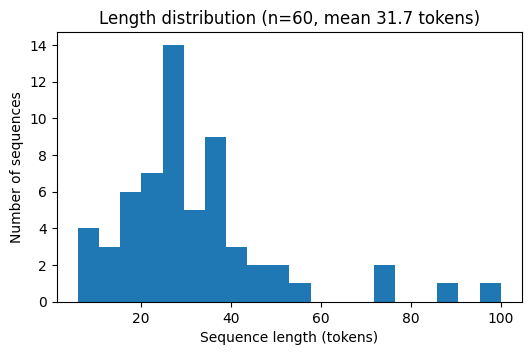

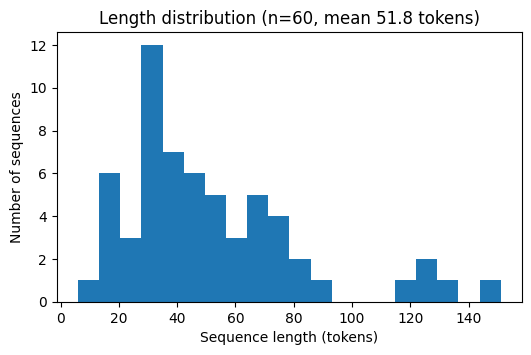

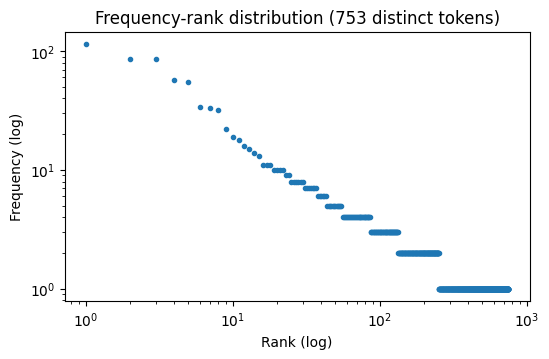

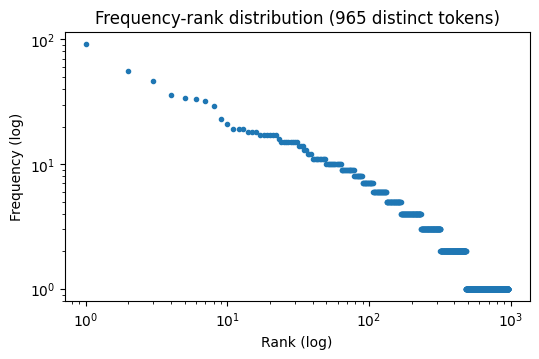

In [10]:
en_length_dist = sequence_length_distribution(english_sentences)
ru_length_dist = sequence_length_distribution(russian_sentences)

en_freq_dist = frequency_rank_distribution(english_sentences)
ru_freq_dist = frequency_rank_distribution(russian_sentences)

Implement a function that uses ancestral sampling on top of p(* | prefix) to generate sequences. This function should also be able to use the temperature parameter of p(* | prefix).

For all four `generate_sequence*` functions, `max_length` is the number of new
tokens, excluding the prefix. Generate exactly that many tokens, including any
sampled EOS tokens; do not stop early at EOS. Return only the continuation and
exclude the prefix from its frequency counts. Use a consistent return representation
across your samplers and retain the generated token boundaries for the counts.


In [9]:
def sample_from(probs: torch.Tensor) -> int:
    """Draw one token id by inverse-CDF sampling; zero-probability tokens are never picked."""
    cdf = torch.cumsum(probs, dim=0)
    u = (1 - torch.rand(1, dtype=cdf.dtype)) * cdf[-1]  # uniform in (0, total]
    return int(torch.searchsorted(cdf, u))

def sample_continuation(prefix: str, temperature: float, max_length: int, truncate=None) -> List[int]:
    """Ancestral sampling of exactly max_length new tokens (EOS included, no early stop).
    Returns only the new token ids. `truncate` zeroes out filtered tokens; we renormalize after."""
    ids = str_to_tokens(prefix)
    new_ids = []
    for _ in range(max_length):
        probs = torch.tensor(next_tok_prob(ids, temperature), dtype=torch.float64)
        if truncate is not None:
            probs = truncate(probs)
            probs = probs / probs.sum()
        tok = sample_from(probs)
        ids.append(tok)
        new_ids.append(tok)
    return new_ids

def summarize(name, samples: List[List[int]]):
    """Print stats for a set of samples and return its vocabulary distribution {token string: count}."""
    counts = Counter(tokens_to_str([t]) for seq in samples for t in seq)
    eos = tokenizer.eos_token_id
    len_before_eos = [seq.index(eos) if eos in seq else len(seq) for seq in samples]
    print(f"{name}: {len(counts)} distinct tokens | mean tokens before first EOS "
          f"{np.mean(len_before_eos):.1f} | top: {counts.most_common(6)}")
    print("   example:", repr(tokens_to_str(samples[0])[:150]))
    return dict(counts)

def plot_rank_curves(dists, title):
    """Overlay frequency-rank curves for several settings."""
    plt.figure(figsize=(6, 3.5))
    for name, counts in dists.items():
        freqs = sorted(counts.values(), reverse=True)
        plt.loglog(range(1, len(freqs) + 1), freqs, label=str(name))
    plt.xlabel("Rank (log)")
    plt.ylabel("Frequency (log)")
    plt.title(title)
    plt.legend()
    plt.show()

In [10]:
def generate_sequence(prefix: str, temperature: float, max_length: int):
    return sample_continuation(prefix, temperature, max_length)

Now use this function to sample 50 texts with max_length of 100 for each temperature value in {0, 0.7, 1, 1.2} using the prefix "hello" and compare their vocabulary distributions.

★ Why might temperature result in the observed differences?

T=0.0: 27 distinct tokens | mean tokens before first EOS 100.0 | top: [('print', 633), ('(h', 633), ('ello', 622), ('[', 572), ('])\n', 533), ('::', 407)]
   example: ' = "Hello World"\nprint(hello)\n\n# String slicing\nprint(hello[0:5])\nprint(hello[0:5])\nprint(hello[0:5:2])\nprint(hello[::2])\nprint(hello[::3])\nprint(hell'
T=0.7: 962 distinct tokens | mean tokens before first EOS 82.9 | top: [('print', 229), ('(h', 116), ('ello', 116), (' "', 99), (' =', 97), (' ', 92)]
   example: ' world\nprint("hello world")\nprint("hello world")\nprint("hello world")\nprint("hello world")\nprint("hello world")\nprint("hello world")\nprint("hello worl'
T=1.0: 1841 distinct tokens | mean tokens before first EOS 92.0 | top: [(' ', 96), ('\n', 89), (',', 83), (' =', 82), (' the', 66), (' to', 56)]
   example: " i created a tiktok video and it's totally cool just need some help with the caption type comment it's a classic comment make sure don't kha here's th"
T=1.2: 3529 distinct tokens | mean toke

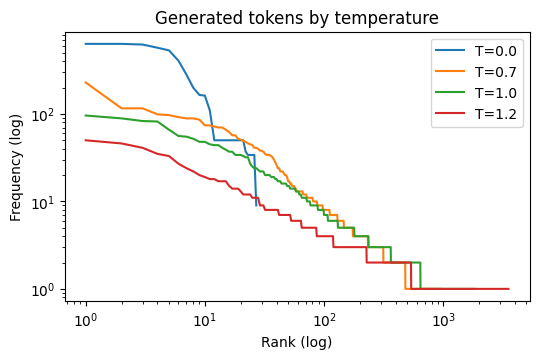

In [13]:
vocab_dist_per_temp = {0.0: None, 0.7: None, 1.0: None, 1.2: None}
# each value in vocab_dist_per_temp maps an observed decoded token string to its count in the generated continuation

# TODO sample 50 texts for each temperature value in {0, 0.7, 1, 1.2} using the prefix "hello" and compare their vocabulary distributions. Why might temperature result in the observed differences?

torch.manual_seed(0)
samples_per_temp = {}
for t in vocab_dist_per_temp:
    samples_per_temp[t] = [generate_sequence("hello", t, 100) for _ in range(50)]
    vocab_dist_per_temp[t] = summarize(f"T={t}", samples_per_temp[t])
plot_rank_curves({f"T={t}": d for t, d in vocab_dist_per_temp.items()}, "Generated tokens by temperature")


with open("results/vocab_distributions_per_temp.json", "w") as f:
    json.dump(vocab_dist_per_temp, f)

Implement a function that modifies and renormalizes p(* | prefix) for ϵ-sampling.

If no token meets the epsilon threshold, use the original distribution without
filtering for that step. Use the same length and prefix conventions as the other
sampling functions.


In [12]:
def generate_sequence_epsilon(prefix: str, temperature: float, epsilon: float, max_length: int):
    #TODO
    def truncate(probs):
        keep = probs >= epsilon
        return probs * keep if keep.any() else probs 
    return sample_continuation(prefix, temperature, max_length, truncate)

Report Use ancestral sampling with temperature = 1 and ϵ in {0, 0.05, 0.1} to sample 50 texts of max length 100 for each value of ϵ using the prefix "hello", and compare their vocabulary distributions.

★ Why might ϵ result in the observed differences?

eps=0.0: 1997 distinct tokens | mean tokens before first EOS 93.4 | top: [(' ', 99), ('1', 80), (' =', 74), (',', 71), (' the', 66), ('\n', 66)]
   example: ', i need a really good yeoman generator that support Angular JS 1.3.\ndo you know pre-built generator?\n\nyeoman is a powerful code generator written in '
eps=0.05: 942 distinct tokens | mean tokens before first EOS 86.6 | top: [('print', 173), ('(h', 152), ('ello', 150), ('#', 125), (' "', 123), (' =', 95)]
   example: '，我有一个问题，就是我有一个字符串，我想把这个字符串按照空格进行拆分，但是这个字符串中可能有多个空格，我想把所有的空格都拆分出来，但是又不希望把空格前面的字符给去掉。比如我有一个字符串是“hello I有问题hello”，我想把所有的空格拆出来，但是又不希望把前面的“hello”给去掉。请告诉我我这'
eps=0.1: 503 distinct tokens | mean tokens before first EOS 86.1 | top: [('print', 372), ('(h', 295), ('ello', 292), ('#', 210), (' "', 170), (' =', 142)]
   example: " = 'Hello World!'\nprint(hello)\nprint(type(hello))\n\n# Delimiter\nprint(hello[0])\nprint(hello[0:5])\nprint(hello[6:])\nprint(hello[:5])\nprint(hello[6:11])\n"


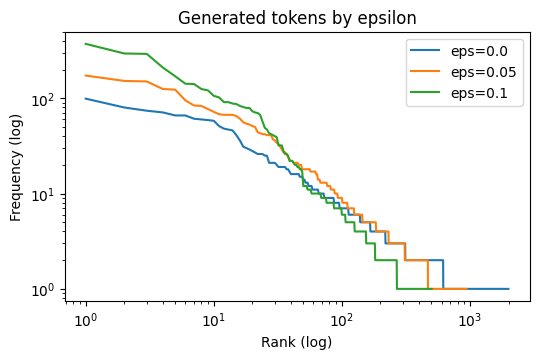

In [15]:
vocab_dist_per_epsilon = {0.0: None, 0.05: None, 0.1: None}
# each value in vocab_dist_per_epsilon maps an observed decoded token string to its count in the generated continuation

# TODO
torch.manual_seed(0)
samples_per_epsilon = {}
for eps in vocab_dist_per_epsilon:
    samples_per_epsilon[eps] = [generate_sequence_epsilon("hello", 1.0, eps, 100) for _ in range(50)]
    vocab_dist_per_epsilon[eps] = summarize(f"eps={eps}", samples_per_epsilon[eps])
plot_rank_curves({f"eps={e}": d for e, d in vocab_dist_per_epsilon.items()}, "Generated tokens by epsilon")

with open("results/vocab_distributions_per_epsilon.json", "w") as f:
    json.dump(vocab_dist_per_epsilon, f)

Implement a function that modifies and renormalizes p(* | prefix) for top-k sampling.

In [13]:
def generate_sequence_top_k(prefix: str, temperature: float, top_k: int, max_length: int):
    #TODO
    def truncate(probs):
        kept = torch.argsort(probs, descending=True)[:top_k]
        filtered = torch.zeros_like(probs)
        filtered[kept] = probs[kept]
        return filtered
    return sample_continuation(prefix, temperature, max_length, truncate)

Report Use ancestral sampling with temperature = 1 and k in {1, 20, 100} to sample 50 texts with max_length 100 tokens for each value of k with the prefix "hello", and compare their vocabulary distributions.

★ Why might k result in the observed differences?

k=1: 27 distinct tokens | mean tokens before first EOS 100.0 | top: [('print', 638), ('(h', 638), ('ello', 630), ('[', 580), ('])\n', 540), ('::', 420)]
   example: ' = "Hello World"\nprint(hello)\n\n# String slicing\nprint(hello[0:5])\nprint(hello[0:5])\nprint(hello[0:5:2])\nprint(hello[::2])\nprint(hello[::3])\nprint(hell'
k=20: 1350 distinct tokens | mean tokens before first EOS 85.9 | top: [('\n', 96), (' =', 87), ('print', 83), (' a', 83), (' ', 81), ('，', 71)]
   example: '，大家好~今天想和大家分享一下，关于在职场遇到挫折，该如何保持积极心态，积极面对和调整心态好，小朋友们也很好~今天我们来聊聊这个话题，首先让我们一起回顾一下，我们如何才能保持健康的生活习惯呢？保持健康的生活习惯是我们，要关注自己的的生活习惯，包括我们吃的习惯，我们的作息习惯，以及我们的锻炼习惯等等，'
k=100: 1595 distinct tokens | mean tokens before first EOS 80.5 | top: [(' =', 90), ('，', 90), ('print', 86), (' ', 80), (' the', 65), (' a', 60)]
   example: " I've been messing around with the new `flutter_core_plugin` package. \nI've wanted to print the name of the plugin when i call the init method from th"


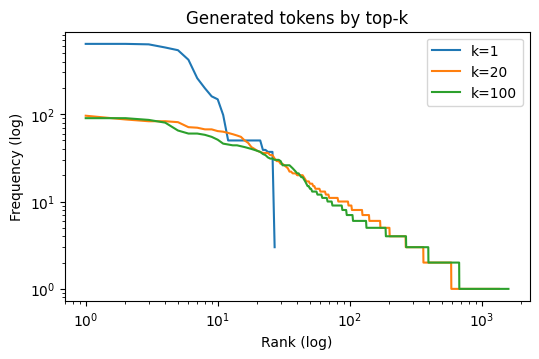

In [17]:
vocab_dist_per_k = {1: None, 20: None, 100: None}
# each value in vocab_dist_per_k maps an observed decoded token string to its count in the generated continuation

# TODO
torch.manual_seed(0)
samples_per_k = {}
for k in vocab_dist_per_k:
    samples_per_k[k] = [generate_sequence_top_k("hello", 1.0, k, 100) for _ in range(50)]
    vocab_dist_per_k[k] = summarize(f"k={k}", samples_per_k[k])
plot_rank_curves({f"k={k}": d for k, d in vocab_dist_per_k.items()}, "Generated tokens by top-k")

with open("results/vocab_distributions_per_k.json", "w") as f:
    json.dump(vocab_dist_per_k, f)

Implement a function that modifies and renormalizes p(* | prefix) for top-p (nucleus) sampling.

In [14]:
def generate_sequence_top_p(prefix: str, temperature: float, top_p: float, max_length: int):
    #TODO
    def truncate(probs):
        if top_p >= 1.0:
            return probs  # keep everything; avoids float round-off dropping tail tokens
        sorted_probs, order = torch.sort(probs, descending=True)
        mass_before = torch.cumsum(sorted_probs, dim=0) - sorted_probs
        kept = order[mass_before < top_p]  # smallest set of top tokens whose mass reaches top_p
        filtered = torch.zeros_like(probs)
        filtered[kept] = probs[kept]
        return filtered
    return sample_continuation(prefix, temperature, max_length, truncate)

Report Use ancestral sampling with temperature = 1 and p in {0.5, 0.9, 1.0} to sample 50 texts with max_length 100 for each value of p with the prefix "hello", and compare their length and vocabulary distributions.

★ Why might p result in the observed differences?

p=0.5: 994 distinct tokens | mean tokens before first EOS 90.5 | top: [('print', 184), ('(h', 159), ('ello', 159), ('0', 157), (' ', 104), ('[', 101)]
   example: ', I am a bit new to python and I am trying to make a program that asks the user for a number and then adds 1 to that number. For example, if the user '
p=0.9: 1528 distinct tokens | mean tokens before first EOS 84.8 | top: [('nn', 89), (' =', 81), (' to', 79), (' the', 75), (' "', 71), ('\n', 67)]
   example: "，我的宝宝13岁，女生，前两天喝酱油嘴唇四周到下巴都红了，去干洗了两天，然后15年我县诊所去复查了，医生也说是感冒了，现在去县医院检查说是肺炎了，请问医生这是传染病问题吗\nIt's important to approach your daughter's symptoms carefully an"
p=1.0: 1864 distinct tokens | mean tokens before first EOS 89.4 | top: [(' =', 101), (' ', 77), ('\n', 76), (' the', 67), (' "', 66), ('print', 57)]
   example: " i created a tiktok video and it's totally cool just need some help with the caption type comment it's a classic comment make sure even we can help yo"


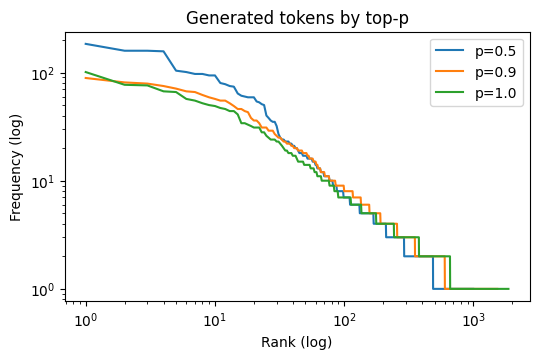

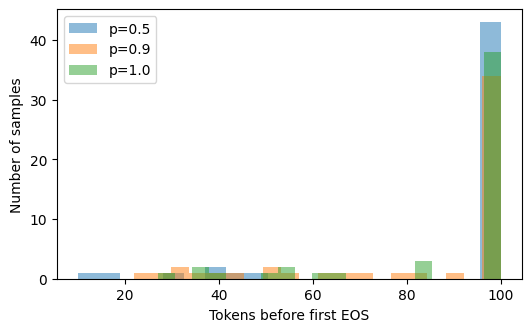

In [19]:
vocab_dist_per_p = {0.5: None, 0.9: None, 1.0: None}
# each value in vocab_dist_per_p maps an observed decoded token string to its count in the generated continuation

# TODO
torch.manual_seed(0)
samples_per_p = {}
for p in vocab_dist_per_p:
    samples_per_p[p] = [generate_sequence_top_p("hello", 1.0, p, 100) for _ in range(50)]
    vocab_dist_per_p[p] = summarize(f"p={p}", samples_per_p[p])
plot_rank_curves({f"p={p}": d for p, d in vocab_dist_per_p.items()}, "Generated tokens by top-p")

eos = tokenizer.eos_token_id
plt.figure(figsize=(6, 3.5))
for p, samples in samples_per_p.items():
    plt.hist([s.index(eos) if eos in s else len(s) for s in samples], bins=20, alpha=0.5, label=f"p={p}")
plt.xlabel("Tokens before first EOS")
plt.ylabel("Number of samples")
plt.legend()
plt.show()

with open("results/vocab_distributions_per_p.json", "w") as f:
    json.dump(vocab_dist_per_p, f)

# 2. Implementing sequence models (25 Points)

The validation perplexities below are targets for checking model performance.
Autograder feedback on exported predictions is not a measurement of those
perplexities; report your achieved validation values in `report.pdf`.


### 2.0 Setup

In [11]:
# Part 1 is complete; release its GPU memory before training the remaining models.
import gc
if "model" in globals():
    del model
gc.collect()
torch.cuda.empty_cache()


In [12]:
# This block handles basic setup and data loading using HuggingFace datasets.

# imports
from collections import defaultdict, Counter
import numpy as np
import math
import tqdm
import random
import pdb

import torch
from torch import nn
import torch.nn.functional as F
from datasets import load_dataset

# Load WikiText2 from HuggingFace
print("Loading WikiText2 dataset from HuggingFace (Salesforce/wikitext)...")
wikitext2 = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

# Process the data to create token lists
def process_wikitext_split(split_data):
    """Convert HuggingFace dataset split to list of tokens."""
    tokens = []
    for example in split_data:
        text = example['text'].strip()
        if text:  # Skip empty lines
            # Simple whitespace tokenization
            tokens.extend(text.split())
    return tokens

train_text = process_wikitext_split(wikitext2['train'])
validation_text = process_wikitext_split(wikitext2['validation'])
test_text = process_wikitext_split(wikitext2['test'])

# Build vocabulary from training data
print("Building vocabulary...")
word_counts = Counter(train_text)

# Create a vocab class to match torchtext interface
class SimpleVocab:
    def __init__(self, word_counts, special_tokens=['<unk>', '<eos>']):
        self.itos = special_tokens.copy()
        self.unk_index = 0  # Index of <unk> token (first special token)
        
        # Build initial stoi mapping
        _stoi = {token: idx for idx, token in enumerate(self.itos)}
        
        # Add all words from training data, sorted by frequency (most common first)
        for word, count in word_counts.most_common():
            if word not in _stoi:
                _stoi[word] = len(self.itos)
                self.itos.append(word)
        
        # Use defaultdict to return <unk> index for unknown words
        # This matches torchtext behavior where unknown words map to <unk>
        self.stoi = defaultdict(lambda: self.unk_index, _stoi)
    
    def __len__(self):
        return len(self.itos)

vocab = SimpleVocab(word_counts)
vocab_size = len(vocab)

print("Data loading complete!")
print("Number of words in the vocabulary: {}".format(vocab_size))
print("Number of tokens in training set: {}".format(len(train_text)))
print("Number of tokens in validation set: {}".format(len(validation_text)))
print("Number of tokens in test set: {}".format(len(test_text)))
print("Example text: {}".format(validation_text[:30]))

Loading WikiText2 dataset from HuggingFace (Salesforce/wikitext)...
Building vocabulary...
Data loading complete!
Number of words in the vocabulary: 76618
Number of tokens in training set: 2051910
Number of tokens in validation set: 213886
Number of tokens in test set: 241211
Example text: ['=', 'Homarus', 'gammarus', '=', 'Homarus', 'gammarus', ',', 'known', 'as', 'the', 'European', 'lobster', 'or', 'common', 'lobster', ',', 'is', 'a', 'species', 'of', 'clawed', 'lobster', 'from', 'the', 'eastern', 'Atlantic', 'Ocean', ',', 'Mediterranean', 'Sea']


We've implemented a unigram model here as a demonstration.

In [13]:
class UnigramModel:
    def __init__(self, train_text):
        self.counts = Counter(train_text)
        self.total_count = len(train_text)

    def probability(self, word):
        return self.counts[word] / self.total_count

    def next_word_probabilities(self, text_prefix):
        """Return a list of probabilities for each word in the vocabulary."""
        return [self.probability(word) for word in vocab.itos]

    def perplexity(self, full_text):
        """Return the perplexity of the model on a text as a float.

        full_text -- a list of string tokens
        """
        log_probabilities = []
        for word in full_text:
            # Note that the base of the log doesn't matter
            # as long as the log and exp use the same base.
            log_probabilities.append(math.log(max(self.probability(word), 1e-8), 2))
        return 2 ** -np.mean(log_probabilities)

unigram_demonstration_model = UnigramModel(train_text)
print('unigram validation perplexity:',
      unigram_demonstration_model.perplexity(validation_text))

def check_validity(model):
    """Performs several sanity checks on your model:
    1) That next_word_probabilities returns a valid distribution
    2) That perplexity matches a perplexity calculated from next_word_probabilities

    Although it is possible to calculate perplexity from next_word_probabilities,
    it is still good to have a separate more efficient method that only computes
    the probabilities of observed words.
    """

    log_probabilities = []
    for i in range(10):
        prefix = validation_text[:i]
        probs = model.next_word_probabilities(prefix)
        assert min(probs) >= 0, "Negative value in next_word_probabilities"
        assert max(probs) <= 1 + 1e-8, "Value larger than 1 in next_word_probabilities"
        assert abs(sum(probs)-1) < 1e-4, "next_word_probabilities do not sum to 1"

        word_id = vocab.stoi[validation_text[i]]
        selected_prob = probs[word_id]
        log_probabilities.append(math.log(selected_prob))

    perplexity = math.exp(-np.mean(log_probabilities))
    your_perplexity = model.perplexity(validation_text[:10])
    assert math.isclose(perplexity, your_perplexity, rel_tol=1e-5, abs_tol=0.1), "your perplexity does not " + \
    "match the one we calculated from `next_word_probabilities`,\n" + \
    "at least one of `perplexity` or `next_word_probabilities` is incorrect.\n" + \
    f"we calcuated {perplexity} from `next_word_probabilities`,\n" + \
    f"but your perplexity function returned {your_perplexity} (on a small sample)."


check_validity(unigram_demonstration_model)


unigram validation perplexity: 2051.6368254004396


To generate from the model, we can sample one word at a time conditioning on the words we have generated so far, just like how we did in the previous part.

In [14]:
# Note: the prefix tokens will be used by our trigram language model
def generate_text(model, n=20, prefix=('<eos>', '<eos>')):
    prefix = list(prefix)
    for _ in range(n):
        probs = model.next_word_probabilities(prefix)
        word = random.choices(vocab.itos, probs)[0]
        prefix.append(word)
    return ' '.join(prefix)

print(generate_text(unigram_demonstration_model))

<eos> <eos> bursary protective = and Manmata Critics First cases VisionLab to . three @-@ notices were complimented was showed which [


You will need to submit some outputs from the models you implement for us to grade. The following function will be used to generate the required output files.

In [15]:
from pathlib import Path
import urllib.request

for filename in ("eval_prefixes.txt", "eval_output_vocab.txt",
                 "eval_prefixes_short.txt", "eval_output_vocab_short.txt"):
    if not Path(filename).exists():
        bundled = source_dir / "data" / filename
        if bundled.exists():
            shutil.copy2(bundled, filename)
        else:
            urllib.request.urlretrieve(
                "https://cal-cs288.github.io/sp21/project_files/proj_1/" + filename, filename)

def save_truncated_distribution(model, filename, short=True):
    """Generate a file of truncated distributions.

    Probability distributions over the full vocabulary are large,
    so we will truncate the distribution to a smaller vocabulary.

    Please do not edit this function
    """
    vocab_name = 'eval_output_vocab'
    prefixes_name = 'eval_prefixes'

    if short:
      vocab_name += '_short'
      prefixes_name += '_short'

    with open('{}.txt'.format(vocab_name), 'r') as eval_vocab_file:
        eval_vocab = [w.strip() for w in eval_vocab_file]
    eval_vocab_ids = [vocab.stoi[s] for s in eval_vocab]

    all_selected_probabilities = []
    with open('{}.txt'.format(prefixes_name), 'r') as eval_prefixes_file:
        lines = eval_prefixes_file.readlines()
        for line in tqdm.tqdm_notebook(lines, leave=False):
            prefix = line.strip().split(' ')
            probs = model.next_word_probabilities(prefix)
            selected_probs = np.array([probs[i] for i in eval_vocab_ids], dtype=np.float32)
            all_selected_probabilities.append(selected_probs)

    all_selected_probabilities = np.stack(all_selected_probabilities)
    np.save(filename, all_selected_probabilities)
    print('saved', filename)


In [36]:
import builtins

def open(file, mode="r", *args, **kwargs):
    """Make text-mode open() default to UTF-8 (Windows defaults to the system codepage)."""
    if "b" not in mode:
        kwargs.setdefault("encoding", "utf-8")
    return builtins.open(file, mode, *args, **kwargs)


In [17]:
save_truncated_distribution(unigram_demonstration_model, 'results/unigram_demonstration_predictions.npy')

C:\Users\GXT\AppData\Local\Temp\ipykernel_25908\838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/1000 [00:00<?, ?it/s]

saved results/unigram_demonstration_predictions.npy


### 2.1 N-gram Model (5 Points)

Now it's time to implement an n-gram language model.

Because not every n-gram will have been observed in training, use add-alpha smoothing to make sure no output word has probability 0.

$$P(w_2|w_1)=\frac{C(w_1,w_2)+\alpha}{C(w_1)+\alpha\cdot|V|}$$

where $|V|$ is the vocab size and $C$ is the count for the given bigram.  An alpha value around `3e-3`  should work.  Later, we'll replace this smoothing with model backoff. One edge case you will need to handle is at the beginning of the text where you don't have `n-1` prior words.  You can handle this however you like as long as you produce a valid probability distribution, but just using a uniform distribution over the vocabulary is reasonable for the purposes of this project.

A properly implemented bi-gram model should get a perplexity below 1500 on the validation set. Please note that the trigram model will probably have a very high perplexity at this point, due to sparsity issues. We'll correct this below.

**Note**: Do not change the signature of the `next_word_probabilities` and `perplexity` functions.  We will use these as a common interface for all of the different model types.  Make sure these two functions call `n_gram_probability`, because later we are going to override `n_gram_probability` in a subclass.
Also, we suggest pre-computing and caching the counts $C$ when you initialize `NGramModel` for efficiency.

In [37]:
class NGramModel:
    def __init__(self, train_text, n=2, alpha=3e-3):
        # get counts and perform any other setup
        self.n = n
        self.smoothing = alpha

        # YOUR CODE HERE

        # BEGIN SOLUTION
        self.vocab_size = len(vocab)
        # C(w_1..w_n): counts of every n-gram in the training text
        self.ngram_counts = Counter(
            tuple(train_text[i:i + n]) for i in range(len(train_text) - n + 1))
        # C(w_1..w_{n-1}): summed from the n-gram counts so that sum_w C(context, w) == C(context)
        self.context_counts = Counter()
        for ngram, count in self.ngram_counts.items():
            self.context_counts[ngram[:-1]] += count

        # END SOLUTION

    def n_gram_probability(self, n_gram):
        """Return the probability of the last word in an n-gram.

        n_gram -- a list of string tokens
        returns the conditional probability of the last token given the rest.
        """
        assert len(n_gram) == self.n

        # YOUR CODE HERE

        # BEGIN SOLUTION
        n_gram = tuple(n_gram)
        return ((self.ngram_counts[n_gram] + self.smoothing) /
                (self.context_counts[n_gram[:-1]] + self.smoothing * self.vocab_size))


        # END SOLUTION

    def next_word_probabilities(self, text_prefix):
        """Return a list of probabilities for each word in the vocabulary."""

        # YOUR CODE HERE
        # use your function n_gram_probability
        # vocab.itos contains a list of words to return probabilities for

        # BEGIN SOLUTION
        if len(text_prefix) < self.n - 1:
            # not enough context yet: uniform distribution over the vocabulary
            return [1.0 / self.vocab_size] * self.vocab_size
        context = list(text_prefix[len(text_prefix) - (self.n - 1):])
        return [self.n_gram_probability(context + [word]) for word in vocab.itos]


        # END SOLUTION

    def perplexity(self, full_text):
        """ full_text is a list of string tokens
        return perplexity as a float """

        # YOUR CODE HERE
        # use your function n_gram_probability
        # This method should differ a bit from the example unigram model because
        # the first n-1 words of full_text must be handled as a special case.

        # BEGIN SOLUTION
        log_prob_sum = 0.0
        for i in range(len(full_text)):
            if i < self.n - 1:
                prob = 1.0 / self.vocab_size  # same uniform fallback as next_word_probabilities
            else:
                prob = self.n_gram_probability(full_text[i - self.n + 1:i + 1])
            log_prob_sum += math.log(prob)
        return math.exp(-log_prob_sum / len(full_text))

        # END SOLUTION

unigram_model = NGramModel(train_text, 1)
check_validity(unigram_model)
print('unigram validation perplexity:', unigram_model.perplexity(validation_text)) # this should be the almost the same as our unigram model perplexity above

bigram_model = NGramModel(train_text, n=2)
check_validity(bigram_model)
print('bigram validation perplexity:', bigram_model.perplexity(validation_text))

trigram_model = NGramModel(train_text, n=3)
check_validity(trigram_model)
print('trigram validation perplexity:', trigram_model.perplexity(validation_text)) # this won't do very well...

save_truncated_distribution(bigram_model, 'results/bigram_predictions.npy') # this might take a few minutes

unigram validation perplexity: 2188.526379013397
bigram validation perplexity: 1448.8367175110927
trigram validation perplexity: 10155.130827604953


C:\Users\GXT\AppData\Local\Temp\ipykernel_41244\838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/1000 [00:00<?, ?it/s]

saved results/bigram_predictions.npy


Please download `bigram_predictions.npy` once you finish this section so that you can submit it.

Report your bigram validation perplexity in `report.pdf`.  (We will use this to help us calibrate our scoring on the test set.)

<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Include in `report.pdf`:

* Bigram validation perplexity.

We can also generate samples from the model to get an idea of how it is doing.

In [38]:
print(generate_text(bigram_model))

<eos> <eos> Grandison point , IKEA grates Crack Halcyon oxohalides flavour excursion Jilin Paravanathapurana unfathomable linguistic Cenomanian jubilees reinforcements subsequences Arwel Donehoo


We now free up some RAM, **it is important to run the cell below, otherwise you will likely run out of RAM in the Colab runtime.**

In [39]:
# Free up some RAM.
del bigram_model
del trigram_model

### 2.2 N-gram Backoff (5 Points)

This basic model works okay for bigrams, but a better strategy (especially for higher-order models) is to use backoff.  Implement backoff with absolute discounting:
$$
\begin{align}
P\left(w_i|w_{i-n+1}^{i-1}\right)&=\frac{max\left\{C(w_{i-n+1}^i)-\delta,0\right\}}{\sum_{w_i} C\left(w_{i-n+1}^i\right)} + \alpha\left(w_{i-n+1}^{i-1}\right) P\left(w_i|w_{i-n+2}^{i-1}\right) \\
\alpha\left(w_{i-n+1}^{i-1}\right)&=\frac{\delta N_{1+}\left(w_{i-n+1}^{i-1}\right)}{{\sum_{w_i} C\left(w_{i-n+1}^i\right)}}
\end{align}
$$
where $N_{1+}$ is the number of words that appear after the previous $n-1$ words (the number of times the max will select something other than 0 in the first equation).  If $\sum_{w_i} C(w_{i-n+1}^i)=0$, use the lower order model probability directly (the above equations would have a division by 0). We found a discount $\delta$ of 0.9 to work well based on validation performance.  A trigram model with this discount value should get a validation perplexity below 700.

In [40]:
class DiscountBackoffModel(NGramModel):
    def __init__(self, train_text, lower_order_model, n=2, delta=0.9):
        super().__init__(train_text, n=n)
        self.lower_order_model = lower_order_model
        self.discount = delta

        # YOUR CODE HERE

        # BEGIN SOLUTION
        self.distinct_followers = Counter(ngram[:-1] for ngram in self.ngram_counts)

        # END SOLUTION

    def n_gram_probability(self, n_gram):
        assert len(n_gram) == self.n

        # YOUR CODE HERE
        # back off to the lower_order model with n'=n-1 using its n_gram_probability function

        # BEGIN SOLUTION
        n_gram = tuple(n_gram)
        context = n_gram[:-1]
        lower_prob = self.lower_order_model.n_gram_probability(list(n_gram[1:]))

        context_total = self.context_counts[context]  # sum over w of C(context, w)
        if context_total == 0:
            return lower_prob  # unseen context: use the lower-order model directly

        discounted = max(self.ngram_counts[n_gram] - self.discount, 0) / context_total
        backoff_weight = self.discount * self.distinct_followers[context] / context_total
        return discounted + backoff_weight * lower_prob

        # END SOLUTION


bigram_backoff_model = DiscountBackoffModel(train_text, unigram_model, 2)
trigram_backoff_model = DiscountBackoffModel(train_text, bigram_backoff_model, 3)
check_validity(trigram_backoff_model)
print('trigram backoff validation perplexity:', trigram_backoff_model.perplexity(validation_text))

save_truncated_distribution(trigram_backoff_model, 'results/discount_backoff_predictions.npy') # this might take a few minutes

trigram backoff validation perplexity: 678.4869796067352


C:\Users\GXT\AppData\Local\Temp\ipykernel_41244\838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/1000 [00:00<?, ?it/s]

saved results/discount_backoff_predictions.npy


Free up RAM.

In [41]:
# Release models we don't need any more.
del unigram_model
del bigram_backoff_model
del trigram_backoff_model

### 2.3 Smoothed N-gram Model (5 Points)

Now, implement Kneser-Ney to replace the unigram base model.
$$P(w)\propto |\{w':c(w',w) > 0\}|$$
A Kneser-Ney trigram model should get a validation perplexity below 675.

In [42]:
class KneserNeyBaseModel(NGramModel):
    def __init__(self, train_text):
        super().__init__(train_text, n=1)

        # YOUR CODE HERE

        # BEGIN SOLUTION
        distinct_bigrams = set(zip(train_text[:-1], train_text[1:]))
        self.continuation_counts = Counter(w for _, w in distinct_bigrams)
        self.total_continuations = len(distinct_bigrams)  # sum of continuation counts over all w

        # END SOLUTION

    def n_gram_probability(self, n_gram):
        assert len(n_gram) == 1

        # YOUR CODE HERE

        # BEGIN SOLUTION
        return ((self.continuation_counts[n_gram[0]] + self.smoothing) /
                (self.total_continuations + self.smoothing * self.vocab_size))


        # END SOLUTION

kn_base = KneserNeyBaseModel(train_text)
check_validity(kn_base)
bigram_kn_backoff_model = DiscountBackoffModel(train_text, kn_base, 2)
trigram_kn_backoff_model = DiscountBackoffModel(train_text, bigram_kn_backoff_model, 3)
print('trigram Kneser-Ney backoff validation perplexity:', trigram_kn_backoff_model.perplexity(validation_text))

save_truncated_distribution(trigram_kn_backoff_model, 'results/trigram_kn_predictions.npy') # this might take a few minutes

trigram Kneser-Ney backoff validation perplexity: 620.477474319148


C:\Users\GXT\AppData\Local\Temp\ipykernel_41244\838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/1000 [00:00<?, ?it/s]

saved results/trigram_kn_predictions.npy


In [43]:
print(generate_text(trigram_kn_backoff_model))
print(generate_text(trigram_kn_backoff_model, prefix=['What','about']))

<eos> <eos> possibilites a range of Carey 's title went defunct poetry " An purely , such as Guy Fawkes masks beavers
What about the magazine 's football clubs and organizations across the whole lot from prerelease , each other and event of constitutional


Report your trigram backoff perplexities with and without Kneser Ney in `report.pdf`.

<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Include in `report.pdf`:

* Trigram backoff validation perplexity.
* Trigram backoff with Kneser Ney perplexity.

Free up RAM.

In [44]:
# Delete models we don't need.
del kn_base
del bigram_kn_backoff_model
del trigram_kn_backoff_model

If you want to learn more about n-gram language models and smoothing techniques, checkout the following paper: https://people.eecs.berkeley.edu/~klein/cs294-5/chen_goodman.pdf

### 2.4 Neural N-gram Model (5 Points)

In this section, you will implement a neural version of an n-gram model.  The model will use a simple feedforward neural network that takes the previous `n-1` words and outputs a distribution over the next word.

You will use PyTorch to implement the model.  We've provided a little bit of code to help with the data loading using PyTorch's data loaders (https://pytorch.org/docs/stable/data.html)

Use a validation perplexity below 550 as the target for the following suggested architecture and hyperparameters.
* embed the words with dimension 128, then flatten into a single embedding for $n-1$ words (with size $(n-1)*128$)
* run 2 hidden layers with 1024 hidden units, then project down to size 128 before the final layer (ie. 4 layers total).
* use weight tying for the embedding and final linear layer (this made a very large difference in our experiments); you can do this by creating the output layer with `nn.Linear`, then using `F.embedding` with the linear layer's `.weight` to embed the input
* rectified linear activation (ReLU) and dropout 0.1 after first 2 hidden layers. **Note: You will likely find a performance drop if you add a nonlinear activation function after the dimension reduction layer.**
* train for 10 epochs with the Adam optimizer (should take around 15-20 minutes)
* do early stopping based on validation set perplexity (see HW1A)


We encourage you to try other architectures and hyperparameters, and you will likely find some that work better than the ones listed above.  Report your achieved validation perplexity, including when it is above the target.

In [23]:
def ids(tokens):
    return [vocab.stoi[t] for t in tokens]

assert torch.cuda.is_available(), "no GPU found, in Colab go to 'Edit->Notebook settings' and choose a GPU hardware accelerator"

class NeuralNgramDataset(torch.utils.data.Dataset):
    def __init__(self, text_token_ids, n):
        self.text_token_ids = text_token_ids
        self.n = n

    def __len__(self):
        return len(self.text_token_ids)

    def __getitem__(self, i):
        if i < self.n-1:
            prev_token_ids = [vocab.stoi['<eos>']] * (self.n-i-1) + self.text_token_ids[:i]
        else:
            prev_token_ids = self.text_token_ids[i-self.n+1:i]

        assert len(prev_token_ids) == self.n-1

        x = torch.tensor(prev_token_ids)
        y = torch.tensor(self.text_token_ids[i])
        return x, y

class NeuralNGramNetwork(nn.Module):
    # a PyTorch Module that holds the neural network for your model

    def __init__(self, n):
        super().__init__()
        self.n = n

        # YOUR CODE HERE

        # BEGIN SOLUTION
        embed_dim, hidden_dim = 128, 1024
        # output layer; its weight (vocab_size x 128) doubles as the input embedding table (weight tying)
        self.output = nn.Linear(embed_dim, vocab_size)
        self.hidden1 = nn.Linear((n - 1) * embed_dim, hidden_dim)
        self.hidden2 = nn.Linear(hidden_dim, hidden_dim)
        self.project = nn.Linear(hidden_dim, embed_dim)
        self.dropout = nn.Dropout(0.1)
        # END SOLUTION

    def forward(self, x):
        # x is a tensor of inputs with shape (batch, n-1)
        # this function returns a tensor of log probabilities with shape (batch, vocab_size)

        # YOUR CODE HERE

        # BEGIN SOLUTION
        embedded = F.embedding(x, self.output.weight)       # (batch, n-1, 128)
        h = embedded.flatten(start_dim=1)                   # (batch, (n-1)*128)
        h = self.dropout(F.relu(self.hidden1(h)))
        h = self.dropout(F.relu(self.hidden2(h)))
        h = self.project(h)                                 # no activation after the reduction layer
        return F.log_softmax(self.output(h), dim=-1)


        # END SOLUTION

class NeuralNGramModel:
    # a class that wraps NeuralNGramNetwork to handle training and evaluation
    # it's ok if this doesn't work for unigram modeling
    def __init__(self, n):
        self.n = n
        self.network = NeuralNGramNetwork(n).cuda()

    def train(self):
        dataset = NeuralNgramDataset(ids(train_text), self.n)
        train_loader = torch.utils.data.DataLoader(dataset, batch_size=128, shuffle=True)
        # iterating over train_loader with a for loop will return a 2-tuple of batched tensors
        # the first tensor will be previous token ids with size (batch, n-1),
        # and the second will be the current token id with size (batch, )
        # you will need to move these tensors to GPU, e.g. by using the Tensor.cuda() function.

        # this will take some time to run; use tqdm.tqdm_notebook to get a progress bar
        # (see Project 0 for example)

        # YOUR CODE HERE

        # BEGIN SOLUTION
        optimizer = torch.optim.Adam(self.network.parameters(), lr=1e-3)
        best_perplexity, best_state = float('inf'), None
        # patience = 2
        # epochs_without_improvement = 0

        for epoch in range(10):
            self.network.train()
            for x, y in tqdm.tqdm(train_loader, desc=f'epoch {epoch + 1}', leave=False):
                x, y = x.cuda(), y.cuda()
                loss = F.nll_loss(self.network(x), y)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # early stopping: keep the weights with the best validation perplexity
            val_perplexity = self.perplexity(validation_text)
            print(f'epoch {epoch + 1}: validation perplexity {val_perplexity:.2f}')
            if val_perplexity < best_perplexity:
                best_perplexity = val_perplexity
                best_state = {k: v.detach().clone() for k, v in self.network.state_dict().items()}
                # epochs_without_improvement = 0
            # else:
            #     epochs_without_improvement += 1

            #     if epochs_without_improvement >= patience:
            #         print(f'Early stopping at epoch {epoch + 1}')
            #         break
        self.network.load_state_dict(best_state)
        print(f'restored best weights (validation perplexity {best_perplexity:.2f})')


        # END SOLUTION

    def next_word_probabilities(self, text_prefix):
        # YOUR CODE HERE
        # don't forget self.network.eval()
        # you will need to convert text_prefix from strings to numbers with the `ids` function
        # if your `perplexity` function below is based on a NeuralNgramDataset DataLoader, you will need to use the same strategy for prefixes with less than n-1 tokens to pass the validity check
        #   the data loader appends extra "<eos>" (end of sentence) tokens to the start of the input so there are always enough to run the network

        # BEGIN SOLUTION
        self.network.eval()
        context = ids(text_prefix[len(text_prefix) - (self.n - 1):] if len(text_prefix) >= self.n - 1 else text_prefix)
        context = [vocab.stoi['<eos>']] * (self.n - 1 - len(context)) + context  # same padding as the dataset
        with torch.no_grad():
            log_probs = self.network(torch.tensor([context]).cuda())
        return log_probs.exp().squeeze(0).tolist()

        # END SOLUTION

    def perplexity(self, text):
        # you may want to use a DataLoader here with a NeuralNgramDataset
        # don't forget self.network.eval()

        # YOUR CODE HERE

        # BEGIN SOLUTION
        self.network.eval()
        loader = torch.utils.data.DataLoader(NeuralNgramDataset(ids(text), self.n), batch_size=1024)
        total_nll = 0.0
        with torch.no_grad():
            for x, y in loader:
                x, y = x.cuda(), y.cuda()
                total_nll += F.nll_loss(self.network(x), y, reduction='sum').item()
        return math.exp(total_nll / len(text))

        # END SOLUTION


neural_trigram_model = NeuralNGramModel(3)
check_validity(neural_trigram_model)
neural_trigram_model.train()
print('neural trigram validation perplexity:', neural_trigram_model.perplexity(validation_text))

save_truncated_distribution(neural_trigram_model, 'results/neural_trigram_predictions.npy', short=False)

epoch 1: validation perplexity 583.77


epoch 2: validation perplexity 541.62


epoch 3: validation perplexity 541.04


epoch 4: validation perplexity 600.00


epoch 5: validation perplexity 622.30


...

epoch 9: validation perplexity 970.56


epoch 10: validation perplexity 1173.91
restored best weights (validation perplexity 541.04)
neural trigram validation perplexity: 541.0355138361431


C:\Users\GXT\AppData\Local\Temp\ipykernel_33488\838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/5000 [00:00<?, ?it/s]

saved results/neural_trigram_predictions.npy


Report your neural trigram perplexity in `report.pdf`.

<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Include in `report.pdf`:

* Neural trigram validation perplexity.

Free up RAM.

In [24]:
# Delete model we don't need.
del neural_trigram_model

### 2.5 LSTM Model (5 Points)

For this stage of the project, you will implement an LSTM language model.

For recurrent language modeling, the data batching strategy is a bit different from what is used in some other tasks.  Sentences are concatenated together so that one sentence starts right after the other, and an unfinished sentence will be continued in the next batch.  The provided `BPTTIterator` below manages this batching with the same interface.  To properly deal with this input format, you should save the last state of the LSTM from a batch to feed in as the first state of the next batch.  When you save state across different batches, you should call `.detach()` on the state tensors before the next batch to tell PyTorch not to backpropagate gradients through the state into the batch you have already finished (which will cause a runtime error).

Use a validation perplexity below 350 as your target. The following architecture and hyperparameters are suggested starting points.
* 3 LSTM layers with 512 units
* dropout of 0.5 after each LSTM layer
* instead of projecting directly from the last LSTM output to the vocabulary size for softmax, project down to a smaller size first (e.g. 512->128->vocab_size). **NOTE: You may find that adding nonlinearities between these layers can hurt performance, try without first.**
* use the same weights for the embedding layer and the pre-softmax layer; dimension 128
* train with Adam (using default learning rates) for at least 20 epochs


In [27]:
# Create datasets for the LSTM model
# Since we're using a custom implementation, we need to create a BPTT iterator

class LanguageModelingDataset:
    """Simple dataset wrapper for language modeling."""
    def __init__(self, text_tokens):
        # Convert tokens to indices
        self.data = torch.tensor(ids(text_tokens), dtype=torch.long)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

class BPTTIterator:
    """Custom BPTT (Backpropagation Through Time) iterator.

    This mimics the behavior of torchtext.data.BPTTIterator.
    """
    def __init__(self, dataset, batch_size, bptt_len, device):
        self.data = dataset.data.to(device)
        self.batch_size = batch_size
        self.bptt_len = bptt_len
        self.device = device

        # Calculate number of batches
        # We divide the data into batch_size chunks
        self.n_tokens = (len(self.data) // batch_size) * batch_size
        self.data = self.data[:self.n_tokens].view(batch_size, -1).t().contiguous()

    def __iter__(self):
        for i in range(0, self.data.size(0) - 1, self.bptt_len):
            seq_len = min(self.bptt_len, self.data.size(0) - 1 - i)
            # Create batch object with .text and .target attributes
            batch = type('obj', (object,), {
                'text': self.data[i:i+seq_len],
                'target': self.data[i+1:i+1+seq_len]
            })()
            yield batch

    def __len__(self):
        return (self.data.size(0) - 1 + self.bptt_len - 1) // self.bptt_len

# Create a namespace to mimic torchtext.data
class TorchtextData:
    BPTTIterator = BPTTIterator

class TorchtextNamespace:
    data = TorchtextData()

torchtext = TorchtextNamespace()

# Create datasets from the text data
print("Creating LSTM datasets...")
train_dataset = LanguageModelingDataset(train_text)
validation_dataset = LanguageModelingDataset(validation_text)
test_dataset = LanguageModelingDataset(test_text)
print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(validation_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")


Creating LSTM datasets...
Train dataset size: 2051910
Validation dataset size: 213886
Test dataset size: 241211


In [18]:
class LSTMNetwork(nn.Module):
    # a PyTorch Module that holds the neural network for your model

    def __init__(self):
        super().__init__()

        # YOUR CODE HERE

        # BEGIN SOLUTION
        # self.embed_dim, self.hidden_size, self.num_layers = 128, 512, 3
        # # output layer; its weight (vocab_size x 128) doubles as the input embedding table (weight tying)
        # self.output = nn.Linear(self.embed_dim, vocab_size)
        # # nn.LSTM's dropout applies after every layer except the last; self.dropout covers the last
        # self.lstm = nn.LSTM(self.embed_dim, self.hidden_size, num_layers=self.num_layers, dropout=0.3)
        # self.dropout = nn.Dropout(0.3)
        # self.project = nn.Linear(self.hidden_size, self.embed_dim)  # 512 -> 128, no nonlinearity

        self.embed_dim, self.hidden_size, self.num_layers = 128, 512, 3

        self.embedding = nn.Embedding(vocab_size, self.embed_dim)
        self.input_dropout = nn.Dropout(0.5)

        self.lstm = nn.LSTM(
            self.embed_dim,
            self.hidden_size,
            num_layers=self.num_layers,
            dropout=0.5
        )

        self.project = nn.Linear(self.hidden_size, self.embed_dim)
        self.output_dropout = nn.Dropout(0.5)
        # END SOLUTION

    # BEGIN SOLUTION
    def init_state(self, batch_size):
        """Zero (hidden, cell) state with shape (num_layers, batch, hidden_size) each."""
        # weight = self.output.weight
        weight = self.embedding.weight
        zeros = weight.new_zeros(self.num_layers, batch_size, self.hidden_size)
        return (zeros, zeros.clone())
    # END SOLUTION

    def forward(self, x, state):
        """Compute the output of the network.

        Note: In the Pytorch LSTM tutorial, the state variable is named "hidden":
        https://pytorch.org/tutorials/beginner/nlp/sequence_models_tutorial.html

        The torch.nn.LSTM documentation is quite helpful:
        https://pytorch.org/docs/stable/nn.html#lstm

        x - a tensor of int64 inputs with shape (seq_len, batch)
        state - a tuple of two tensors with shape (num_layers, batch, hidden_size)
                representing the hidden state and cell state of the of the LSTM.
        returns a tuple with two elements:
          - a tensor of log probabilities with shape (seq_len, batch, vocab_size)
          - a state tuple returned by applying the LSTM.
        """

        # Note that the nn.LSTM module expects inputs with the sequence
        # dimension before the batch by default.
        # In this case the dimensions are already in the right order,
        # but watch out for this since sometimes people put the batch first

        # YOUR CODE HERE

        # BEGIN SOLUTION
        # embedded = F.embedding(x, self.output.weight)      # (seq_len, batch, 128)
        # lstm_out, state = self.lstm(embedded, state)       # (seq_len, batch, 512)
        # h = self.project(self.dropout(lstm_out))           # (seq_len, batch, 128)
        # return F.log_softmax(self.output(h), dim=-1), state

        # embedded = self.dropout(F.embedding(x, self.output.weight))  # (seq_len, batch, 128) + input dropout
        # lstm_out, state = self.lstm(embedded, state)                 # (seq_len, batch, 512)
        # h = self.project(self.dropout(lstm_out))                     # (seq_len, batch, 128)
        # return F.log_softmax(self.output(h), dim=-1), state

        embedded = self.input_dropout(self.embedding(x))

        lstm_out, state = self.lstm(embedded, state)

        h = self.output_dropout(self.project(lstm_out))

        logits = F.linear(h, self.embedding.weight)

        return F.log_softmax(logits, dim=-1), state

        # END SOLUTION

class LSTMModel:
    "A class that wraps LSTMNetwork to handle training and evaluation."

    def __init__(self):
        self.network = LSTMNetwork().cuda()

    def train(self):
        train_iterator = torchtext.data.BPTTIterator(train_dataset, batch_size=64,
                                                     bptt_len=32, device='cuda')
        # Iterate over train_iterator with a for loop to get batches
        # each batch object has a .text and .target attribute with
        # token id tensors for the input and output respectively.

        # The initial state passed into the LSTM should be set to zero.

        # YOUR CODE HERE

        # BEGIN SOLUTION
        optimizer = torch.optim.Adam(self.network.parameters())  # default lr = 1e-3
        # quarter the learning rate whenever validation perplexity fails to improve
        # scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        #     optimizer,
        #     mode='min',
        #     factor=0.5,
        #     patience=3,
        #     threshold=0.005,
        #     min_lr=1e-5
        # )
        # scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        #     optimizer, mode='min', factor=0.5,
        #     patience=3, threshold=0.005, min_lr=1e-5
        # )
        best_perplexity, best_state = float('inf'), None

        for epoch in range(20):
            self.network.train()
            state = self.network.init_state(64)
            eos = torch.full(
                (1, 64), vocab.stoi['<eos>'],
                dtype=torch.long, device='cuda'
            )

            first_targets = train_iterator.data[0]
            first_log_probs, state = self.network(eos, state)

            first_loss = F.nll_loss(
                first_log_probs[0], first_targets, reduction='sum'
            )
            for batch_index, batch in enumerate(
                tqdm.tqdm(train_iterator, desc=f'epoch {epoch + 1}', leave=False)
            ):
                # carry the state over from the previous batch, but don't backprop into it
                # state = tuple(s.detach() for s in state)
                if batch_index > 0:
                    state = tuple(s.detach() for s in state)
                log_probs, state = self.network(batch.text, state)
                loss = F.nll_loss(log_probs.view(-1, log_probs.size(-1)), batch.target.reshape(-1))
                if batch_index == 0:
                    loss = loss + first_loss / batch.target.numel()
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.network.parameters(), 1.0)  # avoid exploding gradients
                optimizer.step()

            # early stopping: keep the weights with the best validation perplexity
            val_perplexity = self.dataset_perplexity(validation_dataset)
            # scheduler.step(val_perplexity)
            print(f'epoch {epoch + 1}: validation perplexity {val_perplexity:.2f}, '
                  f'lr {optimizer.param_groups[0]["lr"]:.1e}')
            if val_perplexity < best_perplexity:
                best_perplexity = val_perplexity
                best_state = {k: v.detach().clone() for k, v in self.network.state_dict().items()}
        self.network.load_state_dict(best_state)
        print(f'restored best weights (validation perplexity {best_perplexity:.2f})')


        # END SOLUTION

    def next_word_probabilities(self, text_prefix):
        "Return a list of probabilities for each word in the vocabulary."

        prefix_token_tensor = torch.tensor(ids(text_prefix), device='cuda').view(-1, 1)

        # YOUR CODE HERE

        # BEGIN SOLUTION
        self.network.eval()
        if prefix_token_tensor.numel() == 0:  # empty prefix: start from <eos>, like a sentence boundary
            prefix_token_tensor = torch.tensor([[vocab.stoi['<eos>']]], device='cuda')
        with torch.no_grad():
            log_probs, _ = self.network(prefix_token_tensor, self.network.init_state(1))
        return log_probs[-1, 0].exp().tolist()  # distribution after the last prefix token


        # END SOLUTION

    def dataset_perplexity(self, torchtext_dataset):
        "Return perplexity as a float."
        # Your code should be very similar to next_word_probabilities, but
        # run in a loop over batches. Use torch.no_grad() for extra speed.

        iterator = torchtext.data.BPTTIterator(torchtext_dataset, batch_size=64, bptt_len=32, device='cuda')

        # YOUR CODE HERE

        # BEGIN SOLUTION
        self.network.eval()
        total_nll, total_tokens = 0.0, 0
        state = self.network.init_state(64)
        with torch.no_grad():
            for batch in iterator:
                log_probs, state = self.network(batch.text, state)
                total_nll += F.nll_loss(log_probs.view(-1, log_probs.size(-1)),
                                        batch.target.reshape(-1), reduction='sum').item()
                total_tokens += batch.target.numel()
        return math.exp(total_nll / total_tokens)


        # END SOLUTION

In [ ]:


lstm_model = LSTMModel()
lstm_model.train()

print('lstm validation perplexity:', lstm_model.dataset_perplexity(validation_dataset))
save_truncated_distribution(lstm_model, 'results/lstm_predictions.npy', short=False)

# Save the LSTM model for use in section 3.1 (text classification with transfer learning)
print('\nSaving LSTM model checkpoint...')
torch.save(lstm_model.network.state_dict(), 'lstm_model.pt')
print('✓ Saved LSTM model to lstm_model.pt')

epoch 1: validation perplexity 1097.64, lr 1.0e-03


epoch 2: validation perplexity 890.59, lr 1.0e-03


epoch 3: validation perplexity 745.14, lr 1.0e-03


epoch 4: validation perplexity 655.08, lr 1.0e-03


epoch 5: validation perplexity 589.82, lr 1.0e-03


...

epoch 19: validation perplexity 324.04, lr 1.0e-03


epoch 20: validation perplexity 318.38, lr 1.0e-03
restored best weights (validation perplexity 318.38)
lstm validation perplexity: 318.3796823844328


C:\Users\GXT\AppData\Local\Temp\ipykernel_33488\838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/5000 [00:00<?, ?it/s]

saved results/lstm_predictions.npy

Saving LSTM model checkpoint...
✓ Saved LSTM model to lstm_model.pt


<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Report your LSTM validation perplexity in `report.pdf`.

In [35]:
del lstm_model

# 3. Acquiring and using word and sentence representations (25 Points)

### 3.0 Setup

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import numpy as np
from collections import Counter
import tqdm

# Load IMDB dataset
print("Loading IMDB dataset...")
imdb_dataset = load_dataset("imdb")
train_data = imdb_dataset['train']
test_data = imdb_dataset['test']

print(f"Train size: {len(train_data)}")
print(f"Test size: {len(test_data)}")
print(f"Example: {train_data[0]}")


Loading IMDB dataset...
Train size: 25000
Test size: 25000
Example: {'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considere

### 3.1 Text classification (10 Points)

In this section we will use the LSTM model we trained in the previous section, to perform text classification. The hidden state of the LSTM contains rich semantic features about the text it is given. We can use this embedding of the hidden state to provide features for a classifier. Here we will perform sentiment classification, using the LSTM hidden state.

First we will load the lstm model trained in the previous section.

In [20]:
# Load the LSTM language model from section 2 to use as a feature extractor
print("Loading pre-trained LSTM language model from section 2...")
lstm_feature_extractor = LSTMNetwork()
lstm_feature_extractor.load_state_dict(torch.load('lstm_model.pt', map_location='cpu'))
lstm_feature_extractor.eval()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
lstm_feature_extractor = lstm_feature_extractor.to(device)
print(f"✓ Successfully loaded LSTM model on {device}")

# Function to convert IMDB text to WikiText2 vocab indices
def imdb_text_to_wikitext_tokens(text, wikitext_vocab, max_len=256):
    """Convert IMDB text to WikiText2 vocabulary token IDs."""
    # Preserve last fall's IMDB preprocessing: lowercase, then split on whitespace.
    words = text.lower().split()[:max_len]
    # Map to WikiText2 vocab (unknown words will map to <unk>)
    token_ids = [wikitext_vocab.stoi[word] for word in words]
    return token_ids


Loading pre-trained LSTM language model from section 2...
✓ Successfully loaded LSTM model on cuda


Now implement the following function, which should extract features from the LSTM given a list of texts. (HINT: you will have to convert the text into token ids using the same vocab as used to train the LSTM model.)

We will compare two different embeddings to use as features for our MLP classifier:

1) The mean of the final layer embeddings across all tokens in the sequence.
2) The last token final layer embedding.

In [21]:
# Extract LSTM hidden states for all IMDB examples
@torch.no_grad()  # inference only: don't build an autograd graph (it would keep every batch on the GPU)
def extract_lstm_features(lstm_model, texts, wikitext_vocab, embedding_type='mean'):
    """Return a (num_texts, hidden_size) CPU tensor of final-LSTM-layer features.
    embedding_type='mean': average of the final-layer outputs over all tokens.
    embedding_type='last': final-layer output at the last token."""
    assert embedding_type in ('mean', 'last')
    batch_size = 256  # reviews per LSTM forward pass
    lstm_model.eval()
    device = next(lstm_model.parameters()).device
    features = []
    for start in tqdm.tqdm(range(0, len(texts), batch_size), desc=f'{embedding_type} features', leave=False):
        token_lists = [imdb_text_to_wikitext_tokens(t, wikitext_vocab) or [wikitext_vocab.stoi['<eos>']]
                       for t in texts[start:start + batch_size]]
        lengths = torch.tensor([len(toks) for toks in token_lists], device=device)
        # pad at the END: the LSTM is left-to-right, so padding never affects the real tokens' outputs
        padded = torch.zeros(int(lengths.max()), len(token_lists), dtype=torch.long, device=device)
        for j, toks in enumerate(token_lists):
            padded[:len(toks), j] = torch.tensor(toks, device=device)

        embedded = lstm_model.embedding(padded)  # same (tied) embedding the LM was trained with
        outputs, _ = lstm_model.lstm(embedded, lstm_model.init_state(len(token_lists)))  # (seq, batch, 512)

        if embedding_type == 'mean':
            mask = (torch.arange(padded.size(0), device=device)[:, None] < lengths[None, :]).unsqueeze(-1)
            feats = (outputs * mask).sum(dim=0) / lengths[:, None]
        else:
            feats = outputs[lengths - 1, torch.arange(len(token_lists), device=device)]
        features.append(feats.cpu())
    return torch.cat(features)

In [22]:
# Extract features if LSTM model is available 
# Extract features for train and test sets
train_features_mean = extract_lstm_features(
    lstm_feature_extractor, 
    train_data['text'], 
    vocab,  # WikiText2 vocab from section 2
    embedding_type='mean'
)

train_features_last = extract_lstm_features(
    lstm_feature_extractor, 
    train_data['text'], 
    vocab,  # WikiText2 vocab from section 2
    embedding_type='last'
)

test_features_mean = extract_lstm_features(
    lstm_feature_extractor, 
    test_data['text'], 
    vocab,  # WikiText2 vocab from section 2
    embedding_type='mean'
)

test_features_last = extract_lstm_features(
    lstm_feature_extractor, 
    test_data['text'], 
    vocab,  # WikiText2 vocab from section 2
    embedding_type='last'
)

# Save features to disk for reuse
torch.save(train_features_mean, 'imdb_train_lstm_features_mean.pt')
torch.save(train_features_last, 'imdb_train_lstm_features_last.pt')
torch.save(test_features_mean, 'imdb_test_lstm_features_mean.pt')
torch.save(test_features_last, 'imdb_test_lstm_features_last.pt')


Now we will create dataloaders for each of our feature sets.

In [23]:
# Create feature-based dataset
class IMDBFeatureDataset(Dataset):
    """Dataset that uses pre-extracted LSTM features."""
    def __init__(self, features, labels):
        self.features = features
        self.labels = torch.tensor(labels, dtype=torch.long)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]


# Create dataloaders with extracted features
train_dataset_mean = IMDBFeatureDataset(train_features_mean, train_data['label'])
test_dataset_mean = IMDBFeatureDataset(test_features_mean, test_data['label'])

train_dataset_last = IMDBFeatureDataset(train_features_last, train_data['label'])
test_dataset_last = IMDBFeatureDataset(test_features_last, test_data['label'])

train_loader_mean = DataLoader(train_dataset_mean, batch_size=64, shuffle=True)
test_loader_mean = DataLoader(test_dataset_mean, batch_size=64, shuffle=False)

train_loader_last = DataLoader(train_dataset_last, batch_size=64, shuffle=True)
test_loader_last = DataLoader(test_dataset_last, batch_size=64, shuffle=False)


Using these embeddings, train two MLP classifiers. One on the mean embeddings and one on the last embeddings.

Keep all five TODO methods in `MLPClassifier`. `forward(x)` takes a batch of
precomputed features. For `class_prediction`, you may accept either a review
string or one feature vector; document your choice and adjust its input annotation
if needed. It must return a single 0/1 label. `dataset_accuracy` takes a labeled
feature dataset or its DataLoader and returns the fraction classified correctly.

Create and train a separate classifier for each feature type. Fill the result
fields below using the supplied test split, with predictions in its original order.


In [24]:
# MLP Classifier for LSTM features
# Keep all five original TODO methods. train(self) is the fitting exercise here.
# It has no data argument: use instance attributes to choose the mean/last training
# loader and feature type. To toggle module mode, call nn.Module.train(self, mode)
# directly; nn.Module.eval() would otherwise call this custom train with an argument.
class MLPClassifier(nn.Module):
    def __init__(self):
        # YOUR CODE HERE

        # BEGIN SOLUTION
        super().__init__()
        # set these two attributes before calling train(): which features to train on
        self.train_loader = None      # train_loader_mean or train_loader_last
        self.feature_type = None      # 'mean' or 'last' (used by class_prediction)
        self.num_epochs = 10
        in_dim = lstm_feature_extractor.hidden_size  # 512
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2),
        )

        # END SOLUTION
    
    def forward(self, x):
        # YOUR CODE HERE

        # BEGIN SOLUTION
        return self.net(x)  # (batch, 2) logits

        # END SOLUTION

    def train(self):
        # YOUR CODE HERE

        # BEGIN SOLUTION
        assert self.train_loader is not None, "set .train_loader (and .feature_type) before train()"
        device = next(self.parameters()).device
        optimizer = torch.optim.Adam(self.parameters(), lr=1e-3)
        for epoch in range(self.num_epochs):
            nn.Module.train(self, True)
            total_loss, correct, count = 0.0, 0, 0
            for x, y in self.train_loader:
                x, y = x.to(device), y.to(device)
                logits = self(x)
                loss = F.cross_entropy(logits, y)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                total_loss += loss.item() * len(y)
                correct += (logits.argmax(dim=1) == y).sum().item()
                count += len(y)
            print(f'[{self.feature_type}] epoch {epoch + 1}: loss {total_loss / count:.4f}, '
                  f'train acc {correct / count:.4f}')
        nn.Module.train(self, False)

        # END SOLUTION

    def class_prediction(self, text_prefix: str) -> int:
        # YOUR CODE HERE

        # BEGIN SOLUTION
        features = extract_lstm_features(lstm_feature_extractor, [text_prefix], vocab, self.feature_type)
        nn.Module.train(self, False)
        with torch.no_grad():
            logits = self(features.to(next(self.parameters()).device))
        return int(logits.argmax(dim=1).item())

        # END SOLUTION

    def dataset_accuracy(self, dataset) -> float:
        # YOUR CODE HERE

        # BEGIN SOLUTION
        predictions, labels = self.predict(dataset)
        return float((predictions == labels).float().mean().item())

        # END SOLUTION

    # BEGIN SOLUTION
    def predict(self, dataset):
        """Predict a labeled feature Dataset or DataLoader in order. Returns (predictions, labels) CPU tensors."""
        loader = dataset if isinstance(dataset, DataLoader) else DataLoader(dataset, batch_size=256)
        device = next(self.parameters()).device
        nn.Module.train(self, False)
        predictions, labels = [], []
        with torch.no_grad():
            for x, y in loader:
                predictions.append(self(x.to(device)).argmax(dim=1).cpu())
                labels.append(y)
        return torch.cat(predictions), torch.cat(labels)
    # END SOLUTION


★ Report the performance of each method using accuracy, precision, recall, and F1 score. Which method performs the best? Which performs the worst? Why?

In [25]:
mean_classifier = MLPClassifier().to(device)
mean_classifier.train_loader, mean_classifier.feature_type = train_loader_mean, 'mean'
mean_classifier.train()

last_classifier = MLPClassifier().to(device)
last_classifier.train_loader, last_classifier.feature_type = train_loader_last, 'last'
last_classifier.train()

print('mean test accuracy:', mean_classifier.dataset_accuracy(test_loader_mean))
print('last test accuracy:', last_classifier.dataset_accuracy(test_loader_last))
print('example prediction:', mean_classifier.class_prediction("This movie was wonderful, I loved it."))

[mean] epoch 1: loss 0.6623, train acc 0.6028
[mean] epoch 2: loss 0.6246, train acc 0.6513
[mean] epoch 3: loss 0.6099, train acc 0.6687
[mean] epoch 4: loss 0.6005, train acc 0.6767
[mean] epoch 5: loss 0.5965, train acc 0.6820
[mean] epoch 6: loss 0.5911, train acc 0.6858
[mean] epoch 7: loss 0.5883, train acc 0.6889
[mean] epoch 8: loss 0.5840, train acc 0.6928
[mean] epoch 9: loss 0.5819, train acc 0.6902
[mean] epoch 10: loss 0.5776, train acc 0.6961
[last] epoch 1: loss 0.6818, train acc 0.5608
[last] epoch 2: loss 0.6646, train acc 0.5960
[last] epoch 3: loss 0.6566, train acc 0.6099
[last] epoch 4: loss 0.6522, train acc 0.6168
[last] epoch 5: loss 0.6491, train acc 0.6188
[last] epoch 6: loss 0.6454, train acc 0.6216
[last] epoch 7: loss 0.6425, train acc 0.6276
[last] epoch 8: loss 0.6398, train acc 0.6341
[last] epoch 9: loss 0.6378, train acc 0.6310
[last] epoch 10: loss 0.6358, train acc 0.6364
mean test accuracy: 0.6926800012588501
last test accuracy: 0.613319993019104


example prediction: 0


In [28]:
# last_emb_accuracy = None
# mean_emb_accuracy = None

# last_emb_precision = None
# mean_emb_precision = None

# last_emb_recall = None
# mean_emb_recall = None

# last_emb_f1 = None
# mean_emb_f1 = None

# mean_predictions = [] # this should be a list of your 0/1 predictions for each item in the test set
# last_predictions = []
import json
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def test_metrics(classifier, test_loader):
    predictions, labels = classifier.predict(test_loader)  # test_loader has shuffle=False: original order
    predictions, labels = predictions.tolist(), labels.tolist()
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='binary', pos_label=1)
    return accuracy_score(labels, predictions), float(precision), float(recall), float(f1), predictions

mean_emb_accuracy, mean_emb_precision, mean_emb_recall, mean_emb_f1, mean_predictions = test_metrics(mean_classifier, test_loader_mean)
last_emb_accuracy, last_emb_precision, last_emb_recall, last_emb_f1, last_predictions = test_metrics(last_classifier, test_loader_last)

print(f"mean: acc {mean_emb_accuracy:.4f}  P {mean_emb_precision:.4f}  R {mean_emb_recall:.4f}  F1 {mean_emb_f1:.4f}")
print(f"last: acc {last_emb_accuracy:.4f}  P {last_emb_precision:.4f}  R {last_emb_recall:.4f}  F1 {last_emb_f1:.4f}")


with open('results/imdb_lstm_classifier_results.json', 'w') as f:
    json.dump({
        'last_emb_accuracy': last_emb_accuracy,
        'mean_emb_accuracy': mean_emb_accuracy,
        'last_emb_precision': last_emb_precision,
        'mean_emb_precision': mean_emb_precision,
        'last_emb_recall': last_emb_recall,
        'mean_emb_recall': mean_emb_recall,
        'last_emb_f1': last_emb_f1,
        'mean_emb_f1': mean_emb_f1,
        'mean_predictions': mean_predictions,
        'last_predictions': last_predictions,
    }, f)

mean: acc 0.6927  P 0.6919  R 0.6948  F1 0.6933
last: acc 0.6133  P 0.6005  R 0.6771  F1 0.6365


### 3.2 Seq2seq with RNNs (15 Points)

In this section, we'll build and train a sequence-to-sequence RNN model for neural machine translation.

We'll start with a baseline encoder-decoder architecture using bidirectional LSTMs.

We'll use the Multi30k German-English translation dataset and evaluate our models using BLEU scores.

#### Setup

The setup cell installed these packages; now import the required dependencies. These include:
* `torch` for modeling and training
* the provided direct downloader for data collection
* `sentencepiece` for subword tokenization
* `sacrebleu` for BLEU score evaluation


In [29]:
# Standard library imports
import json
import math
import random
import pdb

# Third party imports
import matplotlib.pyplot as plt
import numpy as np
import sacrebleu
import sentencepiece
import torch
import torch.nn as nn
import torch.nn.functional as F
import tqdm.notebook


Before proceeding, let's verify that we're connected to a GPU runtime and that `torch` can detect the GPU.
We'll define a variable `device` here to use throughout the code so that we can easily change to run on CPU for debugging.

In [30]:
assert torch.cuda.is_available()

#### Data

The data for this assignment comes from the [Multi30K dataset](https://arxiv.org/abs/1605.00459), which contains English and German captions for images from Flickr. The provided downloader retrieves the same dataset files directly. We use the Multi30K dataset because it is simpler than standard translation benchmark datasets and allows for models to be trained and evaluated in a matter of minutes rather than days.

We will be translating from German to English in this assignment, but the same techniques apply equally well to any language pair.


In [32]:
# Download Multi30k dataset directly (avoids torchtext compatibility issues)
import os
import urllib.request
import tarfile
from types import SimpleNamespace

def download_and_extract_multi30k():
    """Download and extract Multi30k dataset."""
    base_url = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/"
    files = [
        "train.de.gz", "train.en.gz",
        "val.de.gz", "val.en.gz", 
        "test_2016_flickr.de.gz", "test_2016_flickr.en.gz"
    ]
    
    os.makedirs("multi30k", exist_ok=True)
    
    for filename in files:
        filepath = os.path.join("multi30k", filename)
        if not os.path.exists(filepath.replace('.gz', '')):
            try:
                url = base_url + filename
                urllib.request.urlretrieve(url, filepath)
                # Decompress
                import gzip
                with gzip.open(filepath, 'rb') as f_in:
                    with open(filepath.replace('.gz', ''), 'wb') as f_out:
                        f_out.write(f_in.read())
                os.remove(filepath)  # Remove compressed file
            except Exception as e:
                print(f"Error downloading {filename}: {e}")

def load_multi30k_split(split_name):
    """Load Multi30k split from files."""
    # Map split names to file prefixes
    split_map = {
        'train': 'train',
        'valid': 'val',
        'test': 'test_2016_flickr'
    }
    
    prefix = split_map[split_name]
    de_file = os.path.join("multi30k", f"{prefix}.de")
    en_file = os.path.join("multi30k", f"{prefix}.en")
    
    with open(de_file, 'r', encoding='utf-8') as f_de, \
         open(en_file, 'r', encoding='utf-8') as f_en:
        de_lines = [line.strip() for line in f_de]
        en_lines = [line.strip() for line in f_en]
    
    return [SimpleNamespace(src=de, trg=en) for de, en in zip(de_lines, en_lines)]

# Download dataset if not already present
download_and_extract_multi30k()

# Load the splits
training_data = load_multi30k_split('train')
validation_data = load_multi30k_split('valid')
test_data = load_multi30k_split('test')

Now that we have the data, let's see how large each split is and look at a few examples.

In [33]:
print("Number of training examples:", len(training_data))
print("Number of validation examples:", len(validation_data))
print("Number of test examples:", len(test_data))
print()

for example in training_data[:10]:
  print(example.src)
  print(example.trg)
  print()

Number of training examples: 29000
Number of validation examples: 1014
Number of test examples: 1000

Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.
Two young, White males are outside near many bushes.

Mehrere Männer mit Schutzhelmen bedienen ein Antriebsradsystem.
Several men in hard hats are operating a giant pulley system.

Ein kleines Mädchen klettert in ein Spielhaus aus Holz.
A little girl climbing into a wooden playhouse.

Ein Mann in einem blauen Hemd steht auf einer Leiter und putzt ein Fenster.
A man in a blue shirt is standing on a ladder cleaning a window.

Zwei Männer stehen am Herd und bereiten Essen zu.
Two men are at the stove preparing food.

Ein Mann in grün hält eine Gitarre, während der andere Mann sein Hemd ansieht.
A man in green holds a guitar while the other man observes his shirt.

Ein Mann lächelt einen ausgestopften Löwen an.
A man is smiling at a stuffed lion

Ein schickes Mädchen spricht mit dem Handy während sie langsam die Straße entla

#### Vocabulary

We can use `sentencepiece` to create a joint German-English subword vocabulary from the training corpus. Because the number of training examples is small, we choose a smaller vocabulary size than would be used for large-scale NMT.

In [37]:
args = {
    "pad_id": 0,
    "bos_id": 1,
    "eos_id": 2,
    "unk_id": 3,
    "input": "multi30k/train.de,multi30k/train.en",
    "vocab_size": 8000,
    "model_prefix": "multi30k",
}
combined_args = " ".join(
    "--{}={}".format(key, value) for key, value in args.items())
sentencepiece.SentencePieceTrainer.Train(combined_args)

This creates two files: `multi30k.model` and `multi30k.vocab`. The first is a binary file containing the relevant data for the vocabulary. The second is a human-readable listing of each subword and its associated score.

We can preview the contents of the vocabulary by looking at the first few rows from the human-readable file.

In [ ]:
print("".join(Path("multi30k.vocab").read_text().splitlines(keepends=True)[:30]))

<pad>	0
<s>	0
</s>	0
<unk>	0
.	-2.72718
▁a	-3.21357
▁in	-3.43973
m	-3.78503
▁eine	-3.82141
▁A	-3.86856
s	-4.06457
▁Ein	-4.11399
,	-4.20405
▁the	-4.35217
▁und	-4.5704
▁mit	-4.57911
▁auf	-4.58144
▁on	-4.65674
n	-4.67038
▁Mann	-4.70521
▁is	-4.73988
▁man	-4.75331
▁and	-4.76404
▁	-4.76512
ing	-4.8072
▁of	-4.83344
▁einer	-4.86421
▁with	-4.93426
▁Eine	-4.98902
▁ein	-5.126



As we can see, the vocabulary consists of four special tokens (`<pad>` for padding, `<s>` for beginning of sentence (BOS), `</s>` for end of sentence (EOS), `<unk>` for unknown) and a mixture of German and English words and subwords. In order to ensure reversability, word boundaries are encoded with a special unicode character "▁" (U+2581).

To use the vocabulary, we first need to load it from the binary file produced above.

In [40]:
vocab = sentencepiece.SentencePieceProcessor()
vocab.Load("multi30k.model")

True

The vocabulary object includes a number of methods for working with full sequences or individual pieces. We explore the most relevant ones below. A complete interface can be found on [GitHub](https://github.com/google/sentencepiece/tree/master/python#usage) for reference.

In [41]:
print("Vocabulary size:", vocab.GetPieceSize())
print()

for example in training_data[:3]:
  sentence = example.trg
  pieces = vocab.EncodeAsPieces(sentence)
  indices = vocab.EncodeAsIds(sentence)
  print(sentence)
  print(pieces)
  print(vocab.DecodePieces(pieces))
  print(indices)
  print(vocab.DecodeIds(indices))
  print()

piece = vocab.EncodeAsPieces("the")[0]
index = vocab.PieceToId(piece)
print(piece)
print(index)
print(vocab.IdToPiece(index))

Vocabulary size: 8000

Two young, White males are outside near many bushes.
['▁Two', '▁young', ',', '▁White', '▁males', '▁are', '▁outside', '▁near', '▁many', '▁bushes', '.']
Two young, White males are outside near many bushes.
[42, 54, 12, 2889, 2225, 36, 127, 173, 815, 3513, 4]
Two young, White males are outside near many bushes.

Several men in hard hats are operating a giant pulley system.
['▁Se', 'veral', '▁men', '▁in', '▁hard', '▁hats', '▁are', '▁operating', '▁a', '▁g', 'iant', '▁pull', 'e', 'y', '▁s', 'y', 'ste', 'm', '.']
Several men in hard hats are operating a giant pulley system.
[298, 240, 73, 6, 712, 730, 36, 3106, 5, 631, 1679, 583, 32, 96, 552, 96, 1076, 7, 4]
Several men in hard hats are operating a giant pulley system.

A little girl climbing into a wooden playhouse.
['▁A', '▁little', '▁girl', '▁climbing', '▁in', 'to', '▁a', '▁wooden', '▁play', 'house', '.']
A little girl climbing into a wooden playhouse.
[9, 132, 66, 500, 6, 112, 5, 542, 245, 4599, 4]
A little girl cli

We define some constants here for the first three special tokens that you may find useful in the following sections.

In [42]:
pad_id = vocab.PieceToId("<pad>")
bos_id = vocab.PieceToId("<s>")
eos_id = vocab.PieceToId("</s>")

Note that these tokens will be stripped from the output when converting from word pieces to text. This may be helpful when implementing greedy search and beam search.

In [43]:
sentence = training_data[0].trg
indices = vocab.EncodeAsIds(sentence)
indices_augmented = [bos_id] + indices + [eos_id, pad_id, pad_id, pad_id]
print(vocab.DecodeIds(indices))
print(vocab.DecodeIds(indices_augmented))
print(vocab.DecodeIds(indices) == vocab.DecodeIds(indices_augmented))

Two young, White males are outside near many bushes.
Two young, White males are outside near many bushes.
True


Let's begin by defining a batch iterator for the training data. Given a dataset and a batch size, it will iterate over the dataset and yield pairs of tensors containing the subword indices for the source and target sentences in the batch, respectively.

In [44]:
def make_batch(sentences):
  """Convert a list of sentences into a batch of subword indices.

  Args:
    sentences: A list of sentences, each of which is a string.

  Returns:
    A LongTensor of size (max_sequence_length, batch_size) containing the
    subword indices for the sentences, where max_sequence_length is the length
    of the longest sentence as encoded by the subword vocabulary and batch_size
    is the number of sentences in the batch. A beginning-of-sentence token
    should be included before each sequence, and an end-of-sentence token should
    be included after each sequence. Empty slots at the end of shorter sequences
    should be filled with padding tokens. The tensor should be located on the
    device defined at the beginning of the notebook.
  """
  encoded_sequences = []
  for sentence in sentences:
    indices = vocab.EncodeAsIds(sentence)
    indices_with_special = [bos_id] + indices + [eos_id]
    encoded_sequences.append(torch.tensor(indices_with_special, dtype=torch.long, device=device))
  
  # Use pad_sequence to pad them to the same length
  # pad_sequence with batch_first=False returns shape (max_len, batch_size)
  batch = torch.nn.utils.rnn.pad_sequence(encoded_sequences, batch_first=False, padding_value=pad_id)
  
  return batch

def make_batch_iterator(dataset, batch_size, shuffle=False):
  """Make a batch iterator that yields source-target pairs.

  Args:
    dataset: A torchtext dataset object.
    batch_size: An integer batch size.
    shuffle: A boolean indicating whether to shuffle the examples.

  Yields:
    Pairs of tensors constructed by calling the make_batch function on the
    source and target sentences in the current group of examples. The max
    sequence length can differ between the source and target tensor, but the
    batch size will be the same. The final batch may be smaller than the given
    batch size.
  """

  examples = list(dataset)
  if shuffle:
    random.shuffle(examples)

  for start_index in range(0, len(examples), batch_size):
    example_batch = examples[start_index:start_index + batch_size]
    source_sentences = [example.src for example in example_batch]
    target_sentences = [example.trg for example in example_batch]
    yield make_batch(source_sentences), make_batch(target_sentences)

test_batch = make_batch(["a test input", "a longer input than the first"])
print("Example batch tensor:")
print(test_batch)
assert test_batch.shape[1] == 2
assert test_batch[0, 0] == bos_id
assert test_batch[0, 1] == bos_id
assert test_batch[-1, 0] == pad_id
assert test_batch[-1, 1] == eos_id

Example batch tensor:
tensor([[   1,    1],
        [   5,    5],
        [3966,  354],
        [   6,   60],
        [ 236,    6],
        [ 698,  236],
        [   2,  698],
        [   0, 5285],
        [   0,   13],
        [   0, 3759],
        [   0,    2]], device='cuda:0')


### Implementing a sequence-to-sequence model

With our data and vocabulary loaded, we're now ready to build a baseline sequence-to-sequence model.  Later on we'll add an attention mechanism to the model.

Below we will define the model. It should consist of a bidirectional LSTM encoder that encodes the input sentence into a fixed-size representation, and an LSTM decoder that uses this representation to produce the output sentence.

In [50]:
class Seq2seqBaseline(nn.Module):
  def __init__(self):
    super().__init__()

    # Initialize your model's parameters here. To get started, we suggest
    # setting all embedding and hidden dimensions to 256, using encoder and
    # decoder LSTMs with 2 layers, and using a dropout rate of 0.5.

    # Implementation tip: To create a bidirectional LSTM, you don't need to
    # create two LSTM networks. Instead use nn.LSTM(..., bidirectional=True).

    # YOUR CODE HERE
    

    # BEGIN SOLUTION
    self.vocab_size = vocab.GetPieceSize()
    self.embed_dim, self.hidden_size, self.num_layers = 256, 256, 2

    # one embedding table for both sides: the subword vocabulary is joint German-English
    self.embedding = nn.Embedding(self.vocab_size, self.embed_dim, padding_idx=pad_id)
    self.encoder = nn.LSTM(self.embed_dim, self.hidden_size, num_layers=self.num_layers,
                           dropout=0.5, bidirectional=True)
    # combine forward + backward final states (2 * hidden) into the decoder's initial state (hidden)
    self.bridge_h = nn.Linear(2 * self.hidden_size, self.hidden_size)
    self.bridge_c = nn.Linear(2 * self.hidden_size, self.hidden_size)
    self.decoder = nn.LSTM(self.embed_dim, self.hidden_size, num_layers=self.num_layers, dropout=0.5)
    self.dropout = nn.Dropout(0.3)
    self.output = nn.Linear(self.hidden_size, self.vocab_size)
    # END SOLUTION

  def encode(self, source):
    """Encode the source batch using a bidirectional LSTM encoder.

    Args:
      source: An integer tensor with shape (max_source_sequence_length,
        batch_size) containing subword indices for the source sentences.

    Returns:
      A tuple with three elements:
        encoder_output: The output of the bidirectional LSTM with shape
          (max_source_sequence_length, batch_size, 2 * hidden_size).
        encoder_mask: A boolean tensor with shape (max_source_sequence_length,
          batch_size) indicating which encoder outputs correspond to padding
          tokens. Its elements should be True at positions corresponding to
          padding tokens and False elsewhere.
        encoder_hidden: The final hidden states of the bidirectional LSTM (after
          a suitable projection) that will be used to initialize the decoder.
          This should be a pair of tensors (h_n, c_n), each with shape
          (num_layers, batch_size, hidden_size). Note that the hidden state
          returned by the LSTM cannot be used directly. Its initial dimension is
          twice the required size because it contains state from two directions.

    The first two return values are not required for the baseline model and will
    only be used later in the attention model. If desired, they can be replaced
    with None for the initial implementation.
    """

    # Implementation tip: consider using packed sequences to more easily work
    # with the variable-length sequences represented by the source tensor.
    # See https://pytorch.org/docs/stable/nn.html#torch.nn.utils.rnn.PackedSequence.

    # Implementation tip: there are many simple ways to combine the forward
    # and backward portions of the final hidden state, e.g. addition, averaging,
    # or a linear transformation of the appropriate size. Any of these
    # should let you reach the required performance.

    # Compute a tensor containing the length of each source sequence.
    lengths = torch.sum(source != pad_id, axis=0)

    # YOUR CODE HERE
    

    # BEGIN SOLUTION
    embedded = self.dropout(self.embedding(source))                       # (src_len, batch, 256)
    # packing makes the LSTM stop at each sentence's real end, so the final
    # states come from the last real token, not from padding
    packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths.cpu(), enforce_sorted=False)
    packed_output, (h_n, c_n) = self.encoder(packed)
    encoder_output, _ = nn.utils.rnn.pad_packed_sequence(packed_output, total_length=source.size(0))
    encoder_mask = source == pad_id                                       # True at padding

    # h_n, c_n: (num_layers * 2, batch, hidden), ordered layer by layer as [forward, backward]
    batch_size = source.size(1)
    def merge_directions(state, bridge):
      state = state.view(self.num_layers, 2, batch_size, self.hidden_size)
      return bridge(torch.cat([state[:, 0], state[:, 1]], dim=-1))     # (num_layers, batch, hidden)
    encoder_hidden = (merge_directions(h_n, self.bridge_h), merge_directions(c_n, self.bridge_c))
    return encoder_output, encoder_mask, encoder_hidden

    # END SOLUTION

  def decode(self, decoder_input, initial_hidden, encoder_output, encoder_mask):
    """Run the decoder LSTM starting from an initial hidden state.

    The third and fourth arguments are not used in the baseline model, but are
    included for compatibility with the attention model in the next section.

    Args:
      decoder_input: An integer tensor with shape (max_decoder_sequence_length,
        batch_size) containing the subword indices for the decoder input. During
        evaluation, where decoding proceeds one step at a time, the initial
        dimension should be 1.
      initial_hidden: A pair of tensors (h_0, c_0) representing the initial
        state of the decoder, each with shape (num_layers, batch_size,
        hidden_size).
      encoder_output: The output of the encoder with shape
        (max_source_sequence_length, batch_size, 2 * hidden_size).
      encoder_mask: The output mask from the encoder with shape
        (max_source_sequence_length, batch_size). Encoder outputs at positions
        with a True value correspond to padding tokens and should be ignored.

    Returns:
      A tuple with three elements:
        logits: A tensor with shape (max_decoder_sequence_length, batch_size,
          vocab_size) containing unnormalized scores for the next-word
          predictions at each position.
        decoder_hidden: A pair of tensors (h_n, c_n) with the same shape as
          initial_hidden representing the updated decoder state after processing
          the decoder input.
        attention_weights: This will be implemented later in the attention
          model, but in order to maintain compatible type signatures, we also
          include it here. This can be None or any other placeholder value.
    """

    # These arguments are not used in the baseline model.
    del encoder_output
    del encoder_mask

    # YOUR CODE HERE
    

    # BEGIN SOLUTION
    embedded = self.dropout(self.embedding(decoder_input))               # (dec_len, batch, 256)
    decoder_output, decoder_hidden = self.decoder(embedded, initial_hidden)
    logits = self.output(self.dropout(decoder_output))                   # (dec_len, batch, vocab)
    return logits, decoder_hidden, None
    # END SOLUTION

  def compute_loss(self, source, target):
    """Run the model on the source and compute the loss on the target.

    Args:
      source: An integer tensor with shape (max_source_sequence_length,
        batch_size) containing subword indices for the source sentences.
      target: An integer tensor with shape (max_target_sequence_length,
        batch_size) containing subword indices for the target sentences.

    Returns:
      A scalar float tensor representing cross-entropy loss on the current batch.
    """

    # Implementation tip: don't feed the target tensor directly to the decoder.
    # To see why, note that for a target sequence like <s> A B C </s>, you would
    # want to run the decoder on the prefix <s> A B C and have it predict the
    # suffix A B C </s>.

    # YOUR CODE HERE
    ...

    # BEGIN SOLUTION
    encoder_output, encoder_mask, encoder_hidden = self.encode(source)
    decoder_input, decoder_target = target[:-1], target[1:]               # teacher forcing, shifted by one
    logits, _, _ = self.decode(decoder_input, encoder_hidden, encoder_output, encoder_mask)
    return F.cross_entropy(logits.reshape(-1, self.vocab_size), decoder_target.reshape(-1),
                           ignore_index=pad_id)   
    # END SOLUTION

We define the following functions for training.  This code will run as provided, but you are welcome to modify the training loop to adjust the optimizer settings, add learning rate decay, etc.

In [46]:
def train(model, num_epochs, batch_size, model_file):
  """Train the model and save its best checkpoint.

  Model performance across epochs is evaluated using token-level accuracy on the
  validation set. The best checkpoint obtained during training will be stored on
  disk and loaded back into the model at the end of training.
  """
  optimizer = torch.optim.Adam(model.parameters())
  best_accuracy = 0.0
  for epoch in tqdm.notebook.trange(num_epochs, desc="training", unit="epoch"):
    with tqdm.notebook.tqdm(
        make_batch_iterator(training_data, batch_size, shuffle=True),
        desc="epoch {}".format(epoch + 1),
        unit="batch",
        total=math.ceil(len(training_data) / batch_size)) as batch_iterator:
      model.train()
      total_loss = 0.0
      for i, (source, target) in enumerate(batch_iterator, start=1):
        optimizer.zero_grad()
        loss = model.compute_loss(source, target)
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
        batch_iterator.set_postfix(mean_loss=total_loss / i)
      validation_perplexity, validation_accuracy = evaluate_next_token(
          model, validation_data)
      batch_iterator.set_postfix(
          mean_loss=total_loss / i,
          validation_perplexity=validation_perplexity,
          validation_token_accuracy=validation_accuracy)
      if validation_accuracy > best_accuracy:
        print(
            "Obtained a new best validation accuracy of {:.2f}, saving model "
            "checkpoint to {}...".format(validation_accuracy, model_file))
        torch.save(model.state_dict(), model_file)
        best_accuracy = validation_accuracy
  print("Reloading best model checkpoint from {}...".format(model_file))
  model.load_state_dict(torch.load(model_file))

def evaluate_next_token(model, dataset, batch_size=64):
  """Compute token-level perplexity and accuracy metrics.

  Note that the perplexity here is over subwords, not words.

  This function is used for validation set evaluation at the end of each epoch
  and should not be modified.
  """
  model.eval()
  total_cross_entropy = 0.0
  total_predictions = 0
  correct_predictions = 0
  with torch.no_grad():
    for source, target in make_batch_iterator(dataset, batch_size):
      encoder_output, encoder_mask, encoder_hidden = model.encode(source)
      decoder_input, decoder_target = target[:-1], target[1:]
      logits, decoder_hidden, attention_weights = model.decode(
          decoder_input, encoder_hidden, encoder_output, encoder_mask)
      total_cross_entropy += F.cross_entropy(
          logits.permute(1, 2, 0), decoder_target.permute(1, 0),
          ignore_index=pad_id, reduction="sum").item()
      total_predictions += (decoder_target != pad_id).sum().item()
      correct_predictions += (
          (decoder_target != pad_id) &
          (decoder_target == logits.argmax(2))).sum().item()
  perplexity = math.exp(total_cross_entropy / total_predictions)
  accuracy = 100 * correct_predictions / total_predictions
  return perplexity, accuracy

We can now train the baseline model.

Since we haven't yet defined a decoding method to output an entire string, we will measure performance for now by computing perplexity and the accuracy of predicting the next token given a gold prefix of the output. A correct implementation should get a validation token accuracy above 55%. The training code will automatically save the model with the highest validation accuracy and reload that checkpoint's parameters at the end of training.

In [53]:
# You are welcome to adjust these parameters based on your model implementation.
num_epochs = 40
batch_size = 16

baseline_model = Seq2seqBaseline().to(device)
train(baseline_model, num_epochs, batch_size, "baseline_model.pt")

training:   0%|          | 0/40 [00:00<?, ?epoch/s]

epoch 1:   0%|          | 0/1813 [00:00<?, ?batch/s]

Obtained a new best validation accuracy of 38.40, saving model checkpoint to baseline_model.pt...


epoch 2:   0%|          | 0/1813 [00:00<?, ?batch/s]

Obtained a new best validation accuracy of 43.29, saving model checkpoint to baseline_model.pt...


...

Obtained a new best validation accuracy of 56.95, saving model checkpoint to baseline_model.pt...


epoch 38:   0%|          | 0/1813 [00:00<?, ?batch/s]

epoch 39:   0%|          | 0/1813 [00:00<?, ?batch/s]

epoch 40:   0%|          | 0/1813 [00:00<?, ?batch/s]

Obtained a new best validation accuracy of 56.99, saving model checkpoint to baseline_model.pt...
Reloading best model checkpoint from baseline_model.pt...


**Download your baseline model here.** Once you have a model you are happy with, you are encouraged to download it or save it to your Google Drive in case your session disconnects. The best baseline model has been saved to `baseline_model.pt` in the local filesystem. You will need a trained model while implementing inference below and to generate your final predictions. To download session files from Collab.

For evaluation, we also need to be able to generate entire strings from the model. We'll first define a greedy inference procedure here. Later on, we'll implement beam search.

A correct implementation of should get above 20 BLEU on the validation set.

In [54]:
def predict_greedy(model, sentences, max_length=100):
  """Make predictions for the given inputs using greedy inference.

  Args:
    model: A sequence-to-sequence model.
    sentences: A list of input sentences, represented as strings.
    max_length: The maximum length at which to truncate outputs in order to
      avoid non-terminating inference.

  Returns:
    A list of predicted translations, represented as strings.
  """
  model.eval()
  with torch.no_grad():
    # Encode all source sentences in batch
    source_batch = make_batch(sentences)
    encoder_output, encoder_mask, encoder_hidden = model.encode(source_batch)
    batch_size = source_batch.shape[1]

    decoder_hidden = encoder_hidden
    decoder_input = torch.full((1, batch_size), bos_id, dtype=torch.long, device=device)

    generated_tokens = []
    finished = torch.zeros(batch_size, dtype=torch.bool, device=device)
    for _ in range(max_length):
      logits, decoder_hidden, _ = model.decode(
          decoder_input, decoder_hidden, encoder_output, encoder_mask)
      
      # logits shape: (1, batch_size, vocab_size)
      logits = logits.squeeze(0)  # Shape: (batch_size, vocab_size)
      logits[finished, pad_id] += 1e9
      next_tokens = logits.argmax(dim=1)  # Shape: (batch_size,)
      generated_tokens.append(next_tokens)
      
      finished = finished | (next_tokens == eos_id)
      
      if finished.all():
        break
      
      decoder_input = next_tokens.unsqueeze(0)  # Shape: (1, batch_size)
    
    generated_tokens = torch.stack(generated_tokens)  # Shape: (seq_len, batch_size)
    predictions = []
    for i in range(batch_size):
      tokens = generated_tokens[:, i].tolist()
      if eos_id in tokens:
        eos_idx = tokens.index(eos_id)
        tokens = tokens[:eos_idx]
      prediction = vocab.DecodeIds(tokens)
      predictions.append(prediction)
    return predictions

def evaluate(model, dataset, batch_size=64, method="greedy", model_name=""):
  assert method in {"greedy", "beam"}
  source_sentences = [example.src for example in dataset]
  target_sentences = [example.trg for example in dataset]
  model.eval()
  predictions = []
  with torch.no_grad():
    for start_index in range(0, len(source_sentences), batch_size):
      if method == "greedy":
        prediction_batch = predict_greedy(
            model, source_sentences[start_index:start_index + batch_size])
      else:
        prediction_batch = predict_beam(
            model, source_sentences[start_index:start_index + batch_size])
        prediction_batch = [candidates[0] for candidates in prediction_batch]
      predictions.extend(prediction_batch)
  with open(f"results/{model_name}_seq2seq_predictions_{method}.json", "w") as f:
    json.dump(predictions, f)
  return sacrebleu.corpus_bleu(predictions, [target_sentences]).score

print("Baseline model validation BLEU using greedy search:",
      evaluate(baseline_model, validation_data, model_name="baseline"))

Baseline model validation BLEU using greedy search: 22.230179823778585


In [55]:
def show_predictions(model, num_examples=4, include_beam=False):
  for example in validation_data[:num_examples]:
    print("Input:")
    print(" ", example.src)
    print("Target:")
    print(" ", example.trg)
    print("Greedy prediction:")
    print(" ", predict_greedy(model, [example.src])[0])
    if include_beam:
      print("Beam predictions:")
      for candidate in predict_beam(model, [example.src])[0]:
        print(" ", candidate)
    print()

print("Baseline model sample predictions:")
print()
show_predictions(baseline_model)

Baseline model sample predictions:

Input:
  Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen
Target:
  A group of men are loading cotton onto a truck
Greedy prediction:
  A group of men are loading a truck.

Input:
  Ein Mann schläft in einem grünen Raum auf einem Sofa.
Target:
  A man sleeping in a green room on a couch.
Greedy prediction:
  A man sleeping on a green couch in a chair.

Input:
  Ein Junge mit Kopfhörern sitzt auf den Schultern einer Frau.
Target:
  A boy wearing headphones sits on a woman's shoulders.
Greedy prediction:
  A young boy with a turban sits on a woman's lap.

Input:
  Zwei Männer bauen eine blaue Eisfischerhütte auf einem zugefrorenen See auf
Target:
  Two men setting up a blue ice fishing hut on an iced over lake
Greedy prediction:
  Two men are placing a blue canoe on a sunny day.



# 4. Attention (25 Points)

### 4.1 Sequence-to-sequence model with attention (15 Points)

Next, we extend the seq2seq model from the previous part to include an attention mechanism in the decoder. This circumvents the need to store all information about the source sentence in a fixed-size representation, and should substantially improve performance and convergence time.

Your implementation should use bilinear attention, where the attention distribution over the encoder outputs $e_1, \dots, e_n$ given a decoder LSTM output $d$ is obtained via a softmax of the dot products after a suitable projection to get them to the same size: $w_i \propto \exp ( d^\top W e_i )$. The unnormalized attention logits for encoder outputs corresponding to padding tokens should be offset with a large negative value to ensure that the corresponding attention weights are $0$.

After computing the attention distribution, take a weighted sum of the projected encoder outputs to obtain the attention context $c = \sum_i w_i We_i$, and add this to the decoder output $d$ to obtain the final representation to be passed to the vocabulary projection layer.

In [56]:
class Seq2seqAttention(Seq2seqBaseline):
  def __init__(self):
    super().__init__()

    # Initialize any additional parameters needed for this model that are not
    # already included in the baseline model.

    # YOUR CODE HERE
    

    # BEGIN SOLUTION
    # W in d^T W e_i: projects bidirectional encoder outputs (2 * hidden) to the decoder size (hidden)
    self.attention_projection = nn.Linear(2 * self.hidden_size, self.hidden_size, bias=False)

    # END SOLUTION

  def decode(self, decoder_input, initial_hidden, encoder_output, encoder_mask):
    """Run the decoder LSTM starting from an initial hidden state.

    The third and fourth arguments are not used in the baseline model, but are
    included for compatibility with the attention model in the next section.

    Args:
      decoder_input: An integer tensor with shape (max_decoder_sequence_length,
        batch_size) containing the subword indices for the decoder input. During
        evaluation, where decoding proceeds one step at a time, the initial
        dimension should be 1.
      initial_hidden: A pair of tensors (h_0, c_0) representing the initial
        state of the decoder, each with shape (num_layers, batch_size,
        hidden_size).
      encoder_output: The output of the encoder with shape
        (max_source_sequence_length, batch_size, 2 * hidden_size).
      encoder_mask: The output mask from the encoder with shape
        (max_source_sequence_length, batch_size). Encoder outputs at positions
        with a True value correspond to padding tokens and should be ignored.

    Returns:
      A tuple with three elements:
        logits: A tensor with shape (max_decoder_sequence_length, batch_size,
          vocab_size) containing unnormalized scores for the next-word
          predictions at each position.
        decoder_hidden: A pair of tensors (h_n, c_n) with the same shape as
          initial_hidden representing the updated decoder state after processing
          the decoder input.
        attention_weights: A tensor with shape (max_decoder_sequence_length,
          batch_size, max_source_sequence_length) representing the normalized
          attention weights. This should sum to 1 along the last dimension.
    """

    # Implementation tip: use a large negative number like -1e9 instead of
    # float("-inf") when masking logits to avoid numerical issues.

    # Implementation tip: the function torch.einsum may be useful here.
    # See https://rockt.github.io/2018/04/30/einsum for a tutorial.

    # YOUR CODE HERE
    

    # BEGIN SOLUTION
    embedded = self.dropout(self.embedding(decoder_input))                  # (tgt_len, batch, 256)
    decoder_output, decoder_hidden = self.decoder(embedded, initial_hidden)  # d: (tgt_len, batch, 256)

    projected_encoder = self.attention_projection(encoder_output)           # W e_i: (src_len, batch, 256)
    # attention logits d^T W e_i for every (decoder step t, source position s)
    attention_logits = torch.einsum('tbh,sbh->tbs', decoder_output, projected_encoder)
    # padding positions get a large negative offset so their weight becomes 0 after softmax
    padding = encoder_mask.t().unsqueeze(0)                                  # (1, batch, src_len)
    attention_logits = attention_logits.masked_fill(padding, -1e9)
    attention_weights = F.softmax(attention_logits, dim=-1)                 # sums to 1 over src_len

    # context c = sum_i w_i W e_i, added to the decoder output d
    context = torch.einsum('tbs,sbh->tbh', attention_weights, projected_encoder)
    logits = self.output(self.dropout(decoder_output + context))            # (tgt_len, batch, vocab)
    return logits, decoder_hidden, attention_weights
    # END SOLUTION

As before, we can train an attention model using the provided training code.

A correct implementation should get a validation token accuracy above 64 and a validation BLEU above 36 with greedy search.

In [57]:
# You are welcome to adjust these parameters based on your model implementation.
num_epochs = 10
batch_size = 16

attention_model = Seq2seqAttention().to(device)
train(attention_model, num_epochs, batch_size, "attention_model.pt")
print("Attention model validation BLEU using greedy search:",
      evaluate(attention_model, validation_data, model_name="attention"))

training:   0%|          | 0/10 [00:00<?, ?epoch/s]

epoch 1:   0%|          | 0/1813 [00:00<?, ?batch/s]

Obtained a new best validation accuracy of 52.94, saving model checkpoint to attention_model.pt...


epoch 2:   0%|          | 0/1813 [00:00<?, ?batch/s]

Obtained a new best validation accuracy of 58.09, saving model checkpoint to attention_model.pt...


...

epoch 8:   0%|          | 0/1813 [00:00<?, ?batch/s]

Obtained a new best validation accuracy of 65.62, saving model checkpoint to attention_model.pt...


epoch 9:   0%|          | 0/1813 [00:00<?, ?batch/s]

epoch 10:   0%|          | 0/1813 [00:00<?, ?batch/s]

Obtained a new best validation accuracy of 65.98, saving model checkpoint to attention_model.pt...
Reloading best model checkpoint from attention_model.pt...
Attention model validation BLEU using greedy search: 37.611078503000556


**Download your attention model here.** Once you have a model you are happy with, you are encouraged to download it or save it to your Google Drive in case your session disconnects. The best attention model has been saved to `attention_model.pt` in the local filesystem. You will need a trained model while implementing beam search below and to generate your final predictions.

In [58]:
print("Attention model validation BLEU using greedy search:",
      evaluate(attention_model, validation_data, model_name="attention"))
print()
print("Attention model sample predictions:")
print()
show_predictions(attention_model)

Attention model validation BLEU using greedy search: 37.611078503000556

Attention model sample predictions:

Input:
  Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen
Target:
  A group of men are loading cotton onto a truck
Greedy prediction:
  A group of men are using a tree on a truck.

Input:
  Ein Mann schläft in einem grünen Raum auf einem Sofa.
Target:
  A man sleeping in a green room on a couch.
Greedy prediction:
  A man sleeping on a couch in a green room.

Input:
  Ein Junge mit Kopfhörern sitzt auf den Schultern einer Frau.
Target:
  A boy wearing headphones sits on a woman's shoulders.
Greedy prediction:
  A boy with headphones sitting on the shoulders of a woman.

Input:
  Zwei Männer bauen eine blaue Eisfischerhütte auf einem zugefrorenen See auf
Target:
  Two men setting up a blue ice fishing hut on an iced over lake
Greedy prediction:
  Two men building a blue ice cream lake on a brick lake.



### 4.2 Attention visualization: Analysis (10 Points)

Once you have everything working in the section above, add some code here to visualize the decoder attention learned by the attention model using `matplotlib`.

You may visualize decoder attention on gold source-target pairs from the validation data. You do not need to run any inference.

For this section, let's interpret the attention maps generated by your model. You should include:

★ A figure with attention map plots for 4 sentence pairs from the validation set. We encourage you to look through more maps to aid your analysis, but please only include 4 representative plots in the figure. 

★ A brief discussion over trends you discover in the plots. Do the maps line up with your intuition, are there any surprising alignments? Are there any many-to-one or many-to-many alignments, or mainly one-to-one? Using a tool like Google Translate on substrings may help give some insight into this.

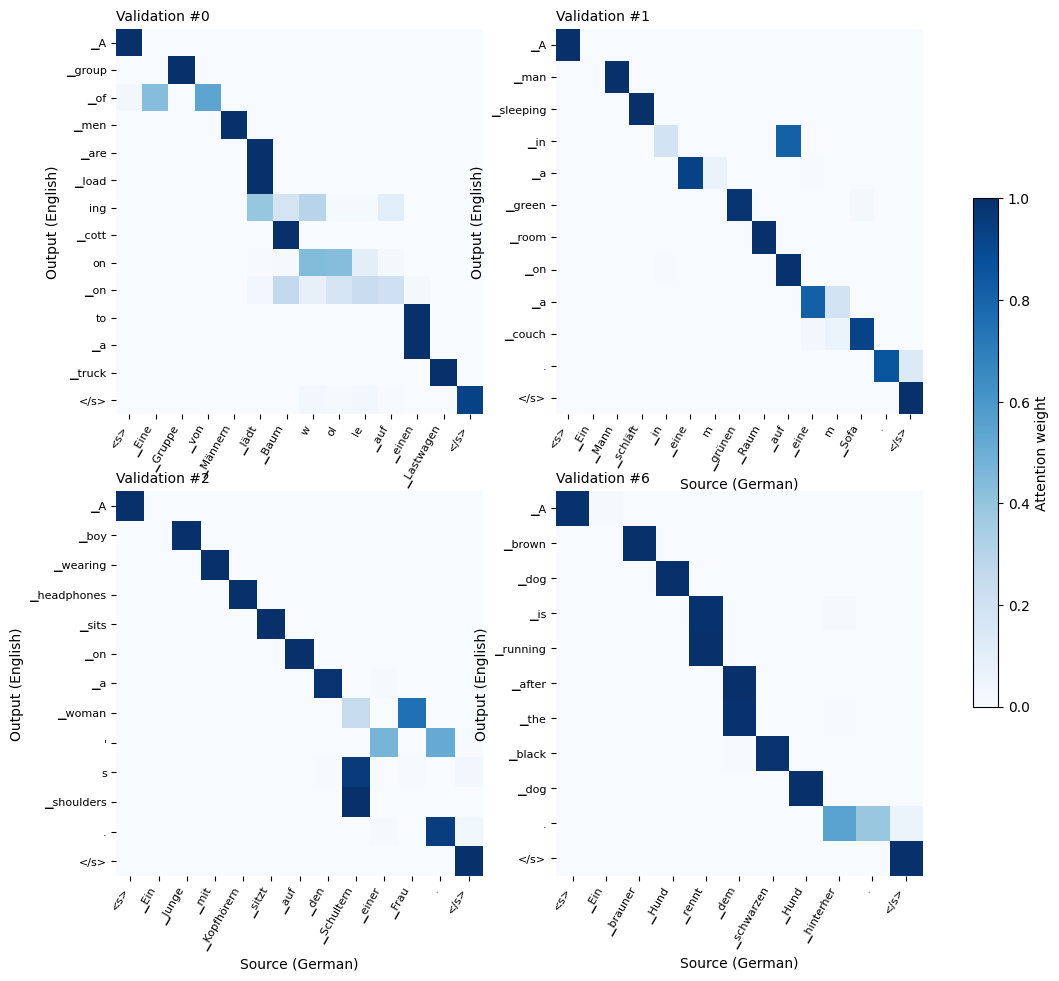

#0  DE: Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen
      EN: A group of men are loading cotton onto a truck
#1  DE: Ein Mann schläft in einem grünen Raum auf einem Sofa.
      EN: A man sleeping in a green room on a couch.
#2  DE: Ein Junge mit Kopfhörern sitzt auf den Schultern einer Frau.
      EN: A boy wearing headphones sits on a woman's shoulders.
#6  DE: Ein brauner Hund rennt dem schwarzen Hund hinterher.
      EN: A brown dog is running after the black dog.


In [59]:
# You may find the following annotated heatmap tutorial helpful:
# https://matplotlib.org/3.1.3/gallery/images_contours_and_fields/image_annotated_heatmap.html.

# YOUR CODE HERE

# BEGIN SOLUTION
def attention_map(model, example):
  """Teacher-forced attention for one gold pair.
  Returns (weights, source_labels, target_labels); weights[t, s] is how much the step
  predicting target token t attends to source token s."""
  model.eval()
  with torch.no_grad():
    source = make_batch([example.src])                 # <s> pieces </s>
    target = make_batch([example.trg])
    encoder_output, encoder_mask, encoder_hidden = model.encode(source)
    _, _, weights = model.decode(target[:-1], encoder_hidden, encoder_output, encoder_mask)
  source_labels = ["<s>"] + vocab.EncodeAsPieces(example.src) + ["</s>"]
  target_labels = vocab.EncodeAsPieces(example.trg) + ["</s>"]  # row t predicts target[t + 1]
  return weights[:, 0, :].cpu().numpy(), source_labels, target_labels

def plot_attention(ax, model, example):
  weights, source_labels, target_labels = attention_map(model, example)
  image = ax.imshow(weights, cmap="Blues", vmin=0, vmax=1, aspect="auto")
  ax.set_xticks(range(len(source_labels)))
  ax.set_xticklabels(source_labels, rotation=60, ha="right", fontsize=8)
  ax.set_yticks(range(len(target_labels)))
  ax.set_yticklabels(target_labels, fontsize=8)
  ax.set_xlabel("Source (German)")
  ax.set_ylabel("Output (English)")
  for spine in ax.spines.values():
    spine.set_visible(False)
  return image

# pick short validation pairs so token labels stay readable; change these indices to explore others
candidate_ids = [i for i, ex in enumerate(validation_data)
                 if len(vocab.EncodeAsPieces(ex.src)) <= 14 and len(vocab.EncodeAsPieces(ex.trg)) <= 14]
example_ids = candidate_ids[:4]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, idx in zip(axes.flat, example_ids):
  image = plot_attention(ax, attention_model, validation_data[idx])
  ax.set_title(f"Validation #{idx}", fontsize=10, loc="left")
fig.colorbar(image, ax=axes, shrink=0.6, label="Attention weight")
fig.savefig("attention_maps.png", dpi=200, bbox_inches="tight")
plt.show()

for idx in example_ids:
  print(f"#{idx}  DE: {validation_data[idx].src}\n      EN: {validation_data[idx].trg}")

# END SOLUTION

Include your attention-map figure and discussion in `report.pdf`.

# 5. Extra Credit: Beam Search (optional; 10 bonus points)

The two beam-search prediction files are required only if you attempt this
extra-credit section. If you skip it, the beam-search check may report missing
predictions; that does not mean your required submission is incomplete.


For extra credit, let's implement beam search.

Similar to greedy search, beam search generates one token at a time. However, rather than keeping only the single best hypothesis, we instead keep the top $k$ candidates at each time step. This is accomplished by computing the set of next-token extensions for each item on the beam and finding the top $k$ across all candidates according to total log-probability.

Candidates that are finished should stay on the beam through the end of inference. The search process concludes once all $k$ items on the beam are complete.

With beam search, you should get an improvement of at least 0.5 BLEU over greedy search, and should reach above 21 BLEU without attention and above 37 BLEU with attention.

**Tips:**

1) A good general strategy when doing complex code like this is to carefully annotate each line with a comment saying what each dimension represents.

2) You should only need one call to topk per step. You do not need to have a topk just over vocabulary first, you can directly go from vocab_size*beam_size to beam_size items.

3) Be sure you are correctly keeping track of which beam item a candidate is selected from and updating the beam states, such as LSTM hidden state, accordingly. A single state from the previous time step may need to be used for multiple new beam items or not at all. This includes all state associated with a beam, including all past tokens output by the beam and any extra tensors such as ones remembering when a beam is finished.

4) Pay attention to how you interleave things when using a single dimension to represent multiple things.  It will make a difference when you start reshaping to separate them out.  It may be easier to start with everything separate, then temporarily combine as needed.

5) For efficiency, we suggest that you implement all beam manipulations using batched PyTorch computations rather than Python for-loops.

6) Once an EOS token has been generated, force the output for that candidate to be padding tokens in all subsequent time steps by adding a large positive number like 1e9 to the appropriate logits. This will ensure that the candidate stays on the beam, as its probability will be very close to 1 and its score will effectively remain the same as when it was first completed.  All other (invalid) token continuations will have extremely low log probability and will not make it onto the beam.

7) While you are encouraged to keep your tensor dimensions constant for simplicity (aside from the sequence length), some special care will need to be taken on the first iteration to ensure that your beam doesn't fill up with k identical copies of the same candidate.


In [ ]:
def predict_beam(model, sentences, k=5, max_length=100):
  """Make predictions for the given inputs using beam search.

  Args:
    model: A sequence-to-sequence model.
    sentences: A list of input sentences, represented as strings.
    k: The size of the beam.
    max_length: The maximum length at which to truncate outputs in order to
      avoid non-terminating inference.

  Returns:
    A list of beam predictions. Each element in the list should be a list of k
    strings corresponding to the top k predictions for the corresponding input,
    sorted in descending order by score.
  """

  # Requirement: your implementation must be batched. This means that you should
  # make only one call to model.encode() at the start of the function, and make
  # only one call to model.decode() per inference step.

  # Return candidates in descending score order and keep completed candidates eligible.

  # YOUR CODE HERE
  ...

  # BEGIN SOLUTION

  # END SOLUTION

print("Baseline model validation BLEU using beam search:",
      evaluate(baseline_model, validation_data, method="beam", model_name="baseline"))
print()
print("Baseline model sample predictions:")
print()
show_predictions(baseline_model, include_beam=True)


In [ ]:
print("Attention model validation BLEU using beam search:",
      evaluate(attention_model, validation_data, method="beam", model_name="attention"))
print()
print("Attention model sample predictions:")
print()
show_predictions(attention_model, include_beam=True)


## Create your submission ZIP

Prepare a separate `report.pdf` with your written answers, requested results,
and figures. In Colab, run the cell below and select the report PDF when prompted.
The helper includes the currently open notebook with your edits and downloads
`submission.zip`. For a local run, first save your completed `hw3.ipynb` and
`report.pdf` in the notebook's working directory.

Upload `submission.zip` to Gradescope. It contains `hw3.ipynb`, `report.pdf`, and the
`.json` and `.npy` files from `results/`, all at the ZIP root. Include both beam-search result
files if you completed the extra-credit section. The helper packages the files
currently present; it does not check completeness or correctness.


In [ ]:
import sys
from make_submission import build_submission, from_colab

if "google.colab" in sys.modules:
    from_colab()
else:
    build_submission()
